# 01. Statistical Biomarker Analysis: Kurtosis & Skewness Across 19-Channel Clinical EEG
### Author: Md. Reazul Islam | Department of Computer Science & Engineering, North Western University / Prospective Fall 2027 M.S. Graduate Researcher
---
## 1. Neurophysiological Context & Dataset Acquisition
This notebook performs exploratory statistical biomarker analysis on primary clinical EEG recordings acquired over a 3-month clinical study at the **Medicine Department of Khulna Medical College and Hospital (Khulna, Bangladesh)**.
- **Clinical Cohort**: 51 screened referrals $\rightarrow$ **32 curated subjects** (16 epileptic seizure-positive patients, 16 non-epileptic controls).
- **Montage**: 19 active scalp channels placed according to the International 10–20 standard:
  Fp1-A1, Fp2-A2, F3-A1, F4-A2, C3-A1, C4-A2, P3-A1, P4-A2, O1-A1, O2-A2, F7-A2, F8-A2, T7-A1, T8-A2, P7-A1, P8-A2, Fz-A1, Pz-A2, Cz-A2.
- **Sampling & Preprocessing**: 200 Hz continuous recording (~1.5 hours per subject). Raw Neuro-Scan (.eeg) recordings were exported to European Data Format (.edf) and filtered via zero-phase FIR bandpass filtering in **MATLAB EEGLAB (v2021.1)** into the **Alpha band (8–13 Hz)**.

## 2. Mathematical Formulations of Statistical Moments
1. **Kurtosis ($)**: Measures the fourth standardized central moment of potential distribution across time:
   K = \frac{\sum_{i=1}^N (x_i - \bar{x})^4}{N \cdot s_x^4}
   Captures sharp, high-amplitude paroxysmal epileptiform spikes versus flatter background activity.
2. **Skewness ($)**: Measures third-order central asymmetry:
   S = \frac{\sum_{i=1}^N (x_i - \bar{x})^3}{(N - 1) \cdot s_x^3}
   Quantifies potential polarity imbalances characteristic of ictal and interictal spike-wave discharges.


## Part I: Kurtosis Distribution & Spatial Correlation Analysis (Alpha Band)

In [1]:
import pandas as pd
My_path = '../data/extracted_features/kur_pos.csv'
ds = pd.read_csv(My_path)

In [2]:
data= ds.dropna()
print(data.head())

      Fp1-A1     Fp2-A2     F3-A1      F4-A2      C3-A1      C4-A2     P3-A1  \
0   1.724046   1.606694  1.337242   1.293023   1.541510   1.352075  1.984068   
1  14.783730   6.372425  1.256308   3.895182  92.119842   4.958966  2.153178   
2   2.789291   1.779556  4.877424   1.680382   3.537057  11.228608  2.120405   
3   0.454994   0.458741  0.391296   0.320689  10.367891  19.664920  0.286798   
4   3.500694  11.814473  2.605626  28.664149   2.133212   9.456639  5.627201   

       P4-A2      O1-A1     O2-A2      F7-A2       F8-A2     T7-A1      T8-A2  \
0   2.372944   6.312917  1.910926   2.992533    6.048669  1.108841   1.094455   
1   2.422057   5.592520  1.691225   5.050606  318.784033  6.346970   6.538263   
2   2.082640  39.879856  7.953224   4.388044    5.508870  2.902622  18.481121   
3   0.180294  29.093888  0.900762  28.222361    0.892233  0.418629   0.646748   
4  95.476664  12.558025  0.189842  38.352979   22.360303  9.612776  25.637918   

        P7-A1     P8-A2       Fz

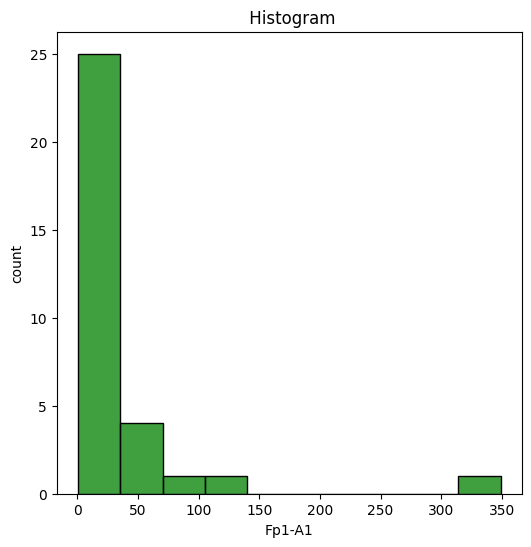

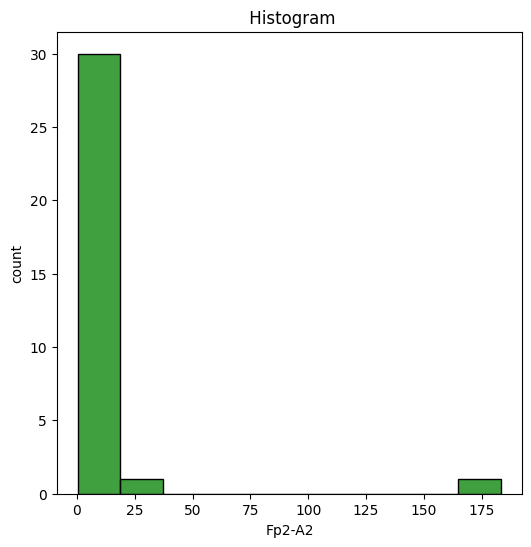

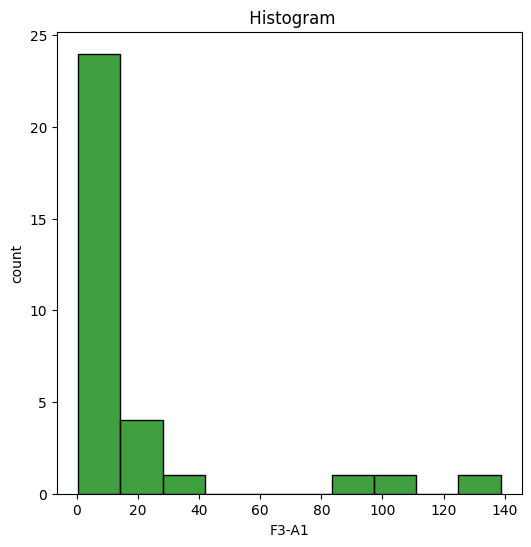

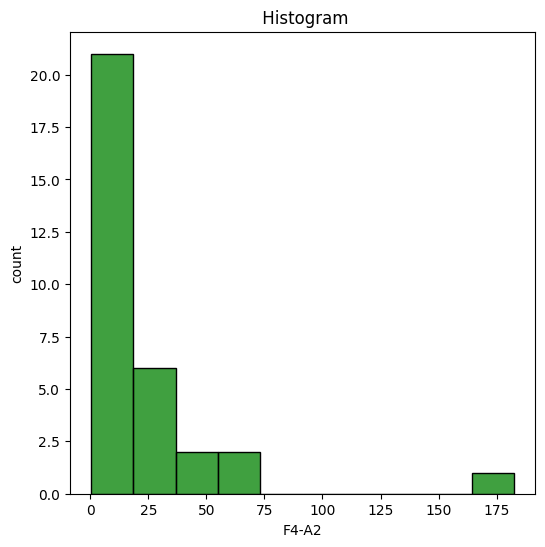

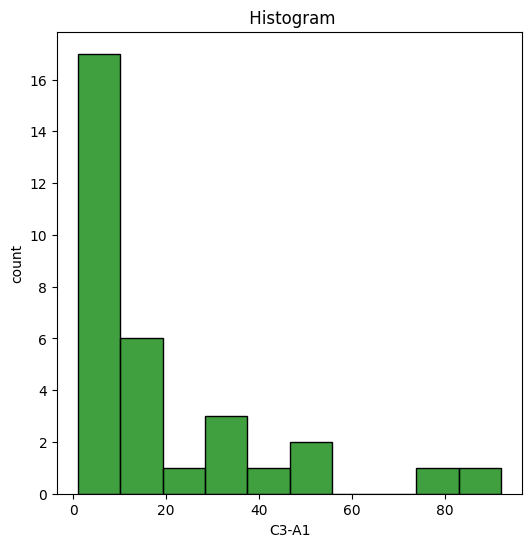

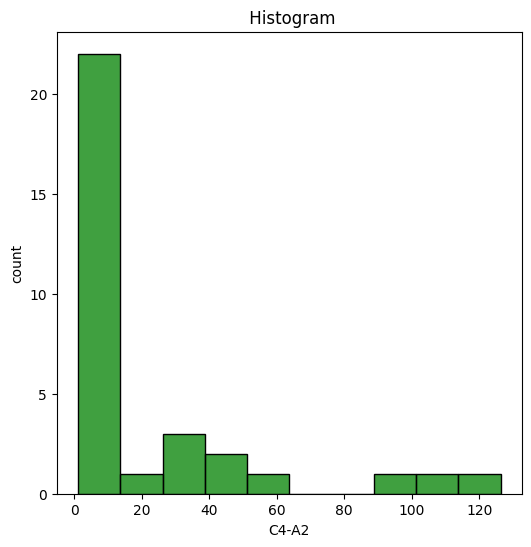

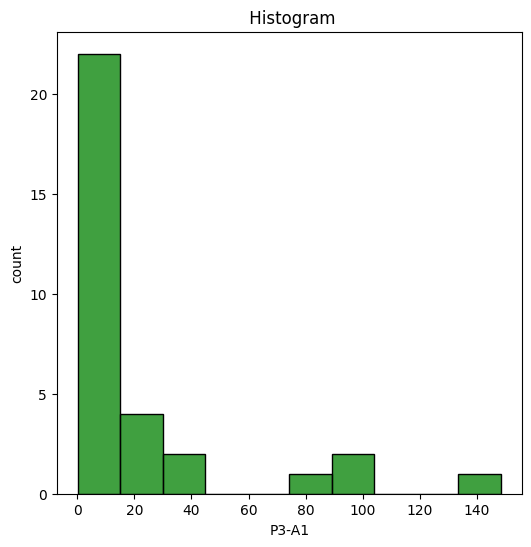

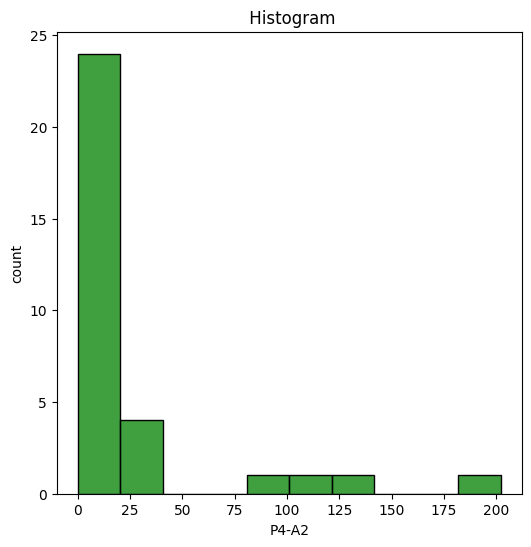

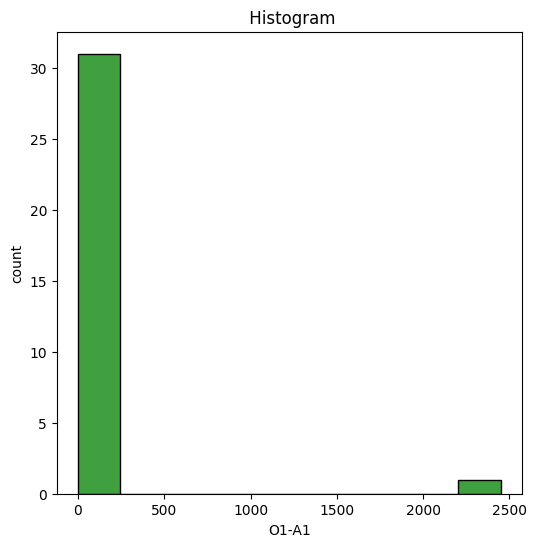

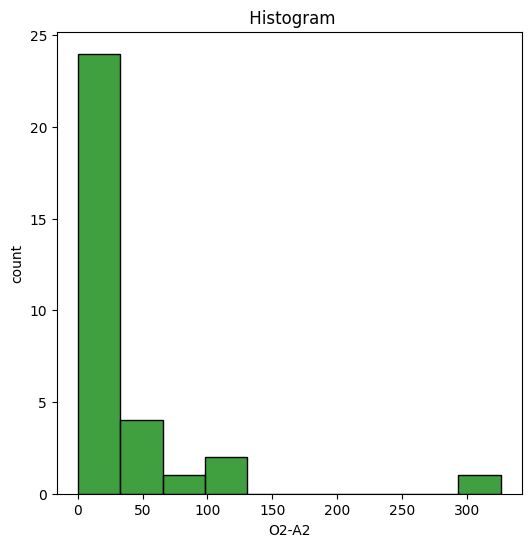

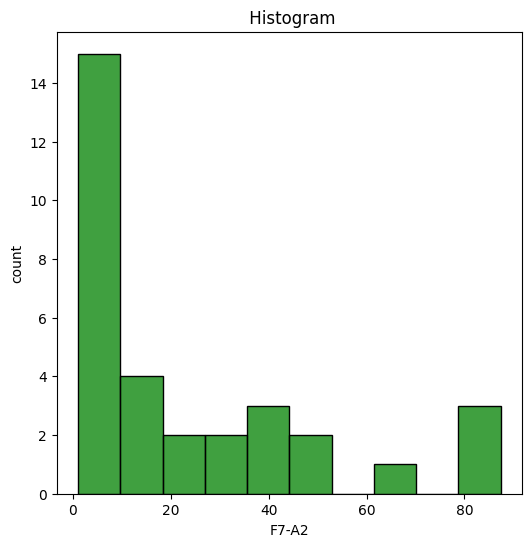

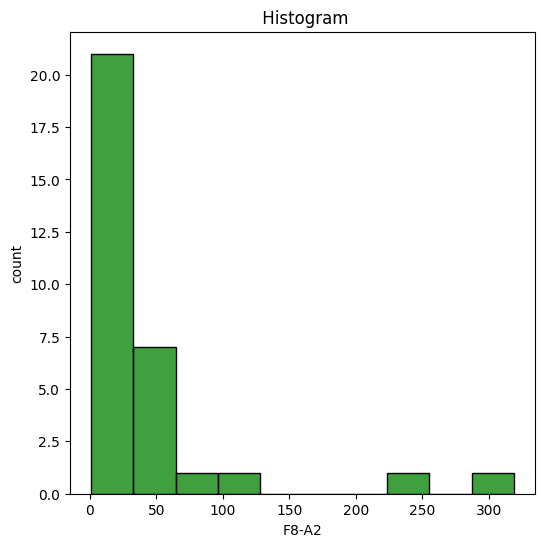

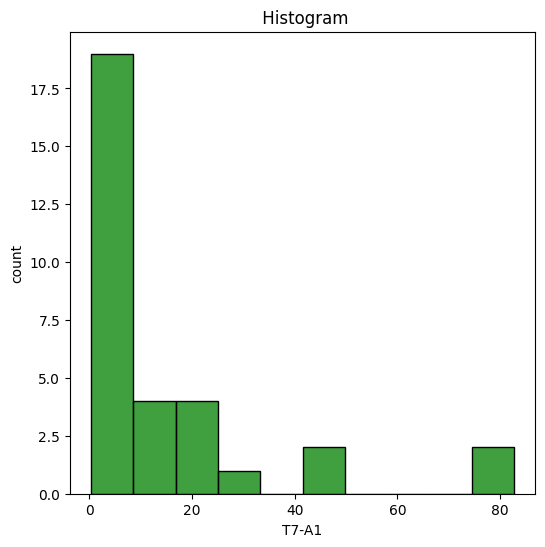

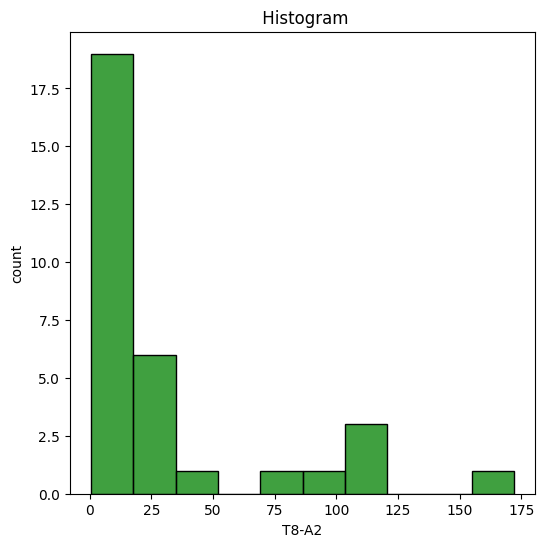

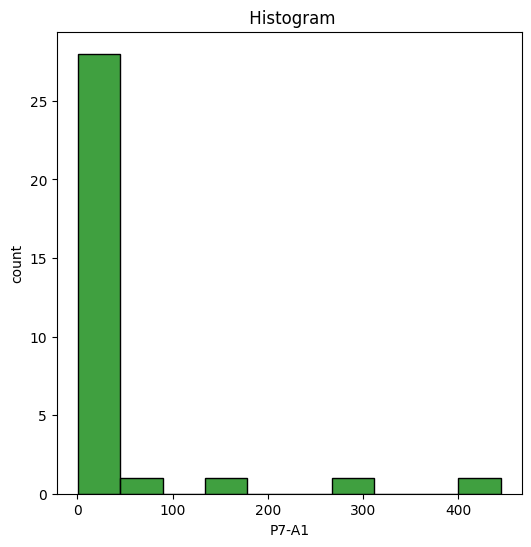

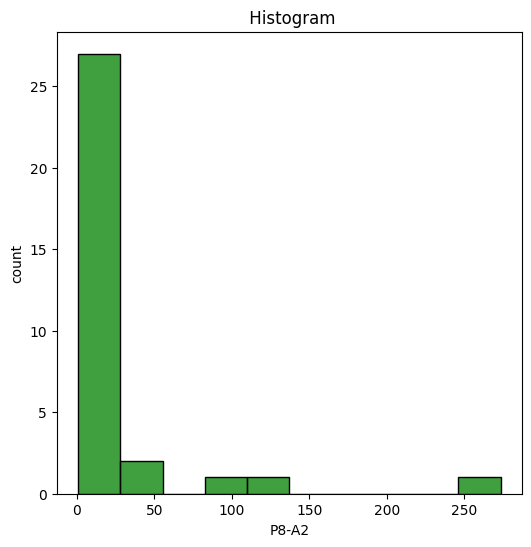

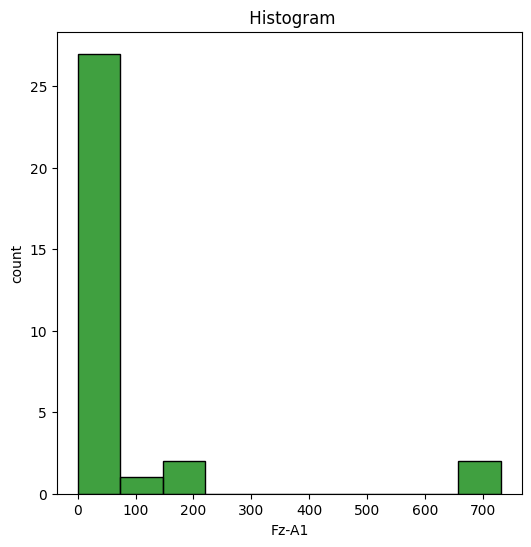

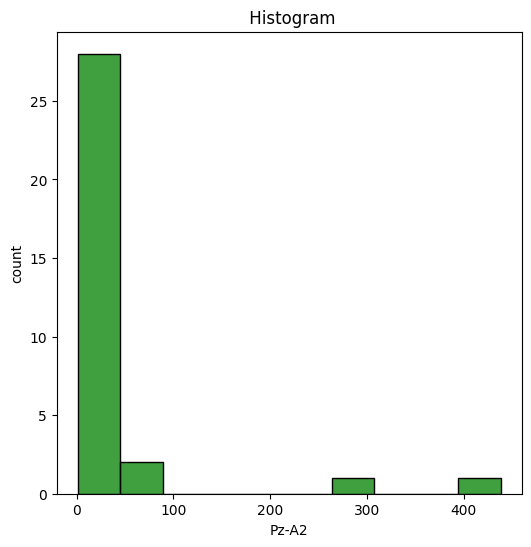

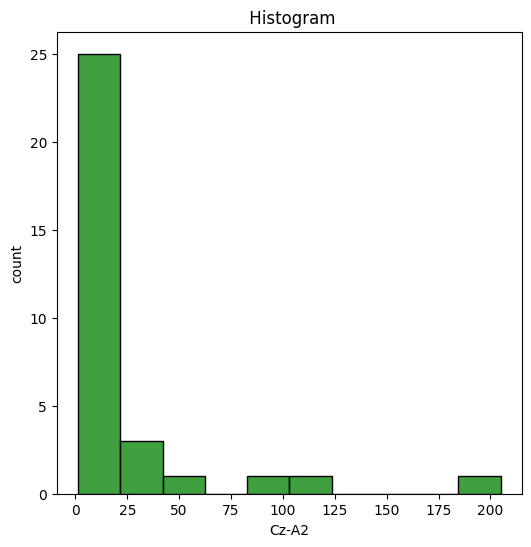

In [3]:
import warnings
warnings.filterwarnings("ignore")
numerical_columns = ds.select_dtypes(include=['int64', 'float64']).columns
for column in numerical_columns:
    import matplotlib.pyplot as plt
    import seaborn as sns

    plt.figure(figsize=(6, 6))
    sns.histplot( x=column, data=ds,bins=10,color='g')
    plt.title(f' Histogram')
    plt.ylabel('count')
    plt.show()

In [4]:
# Select all columns except the last one
selected_columns = data.iloc[:, :-1]

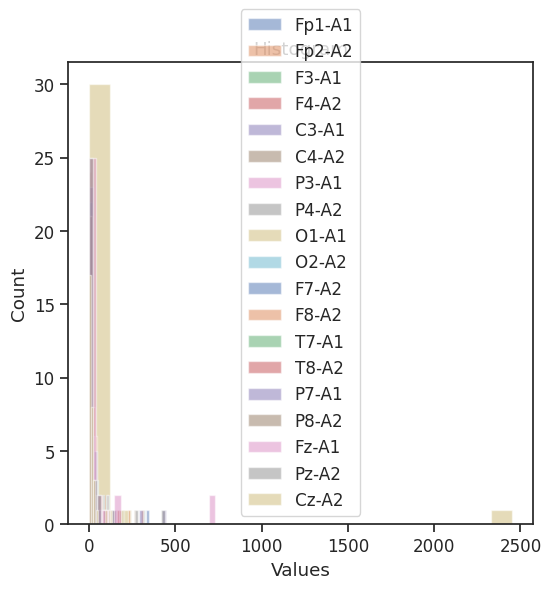

In [5]:
# Histogram
sns.set(style='ticks', palette='deep', font_scale=1.1)
fig, ax = plt.subplots(figsize=(6, 6))
for col in selected_columns.columns:
    plt.hist(selected_columns[col], bins=20, alpha=0.5, label=col)
plt.xlabel('Values')
plt.ylabel('Count')
plt.title('Histogram')
plt.legend()
plt.show()

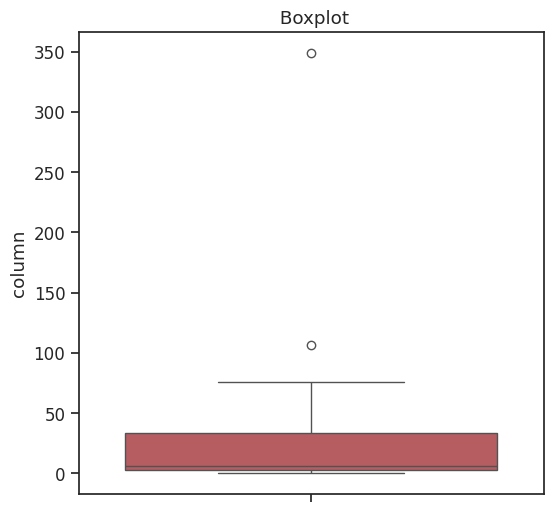

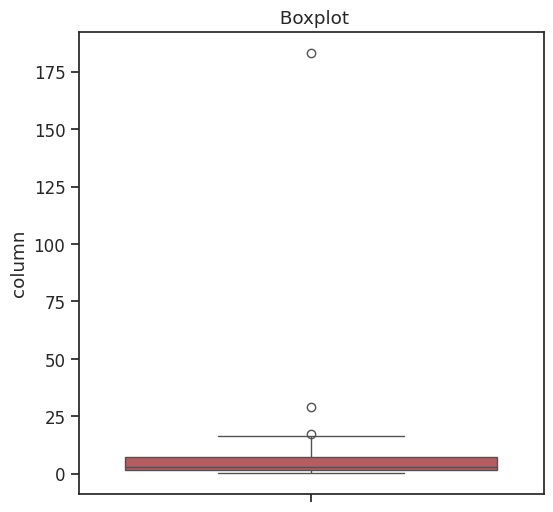

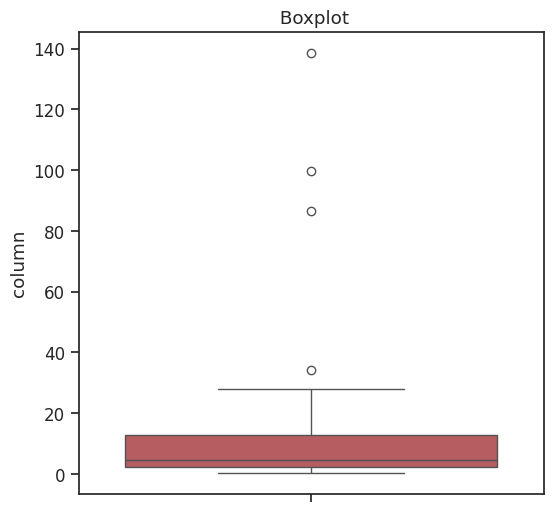

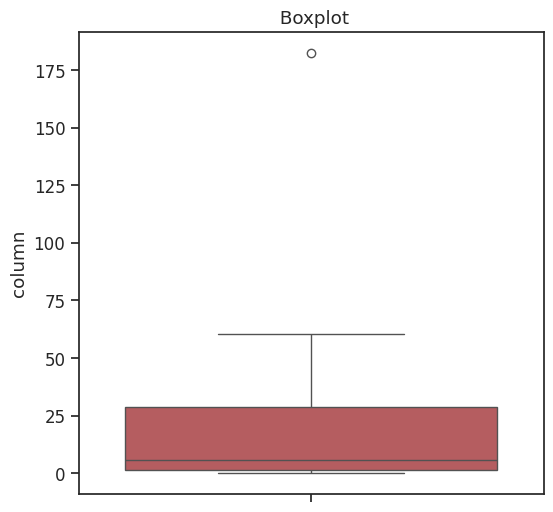

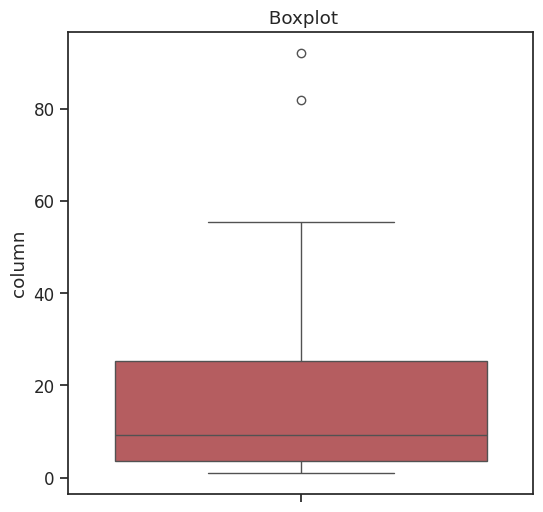

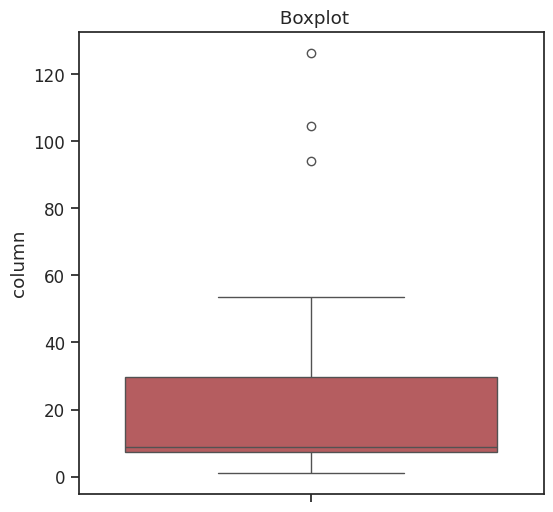

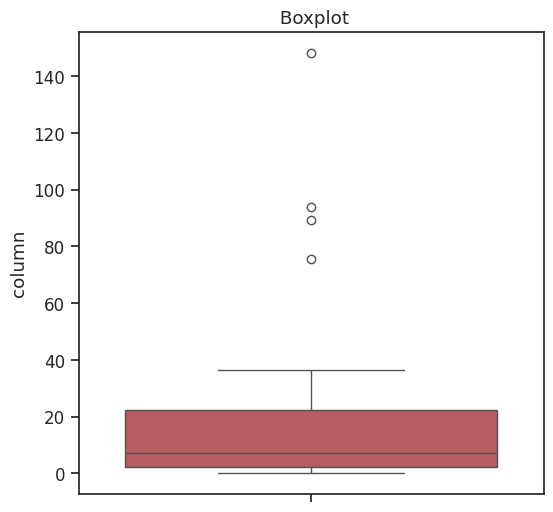

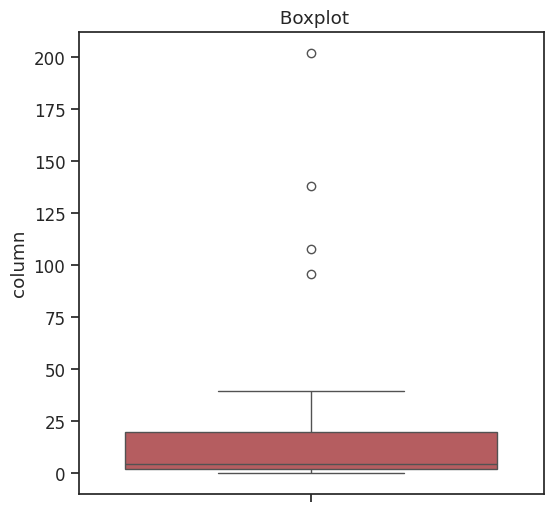

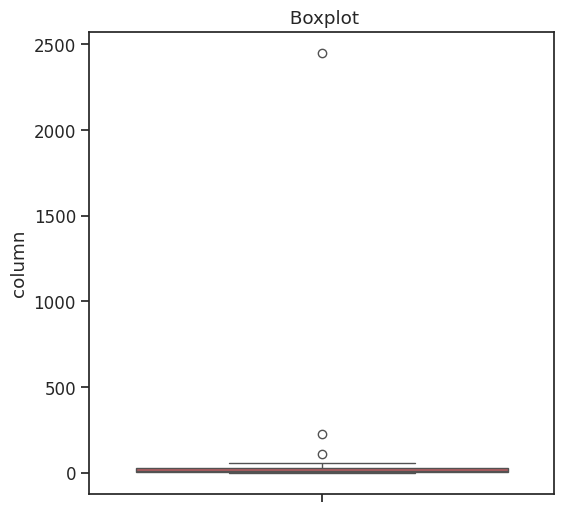

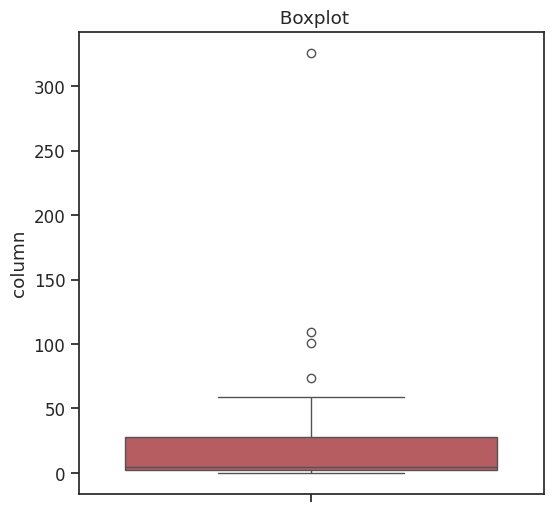

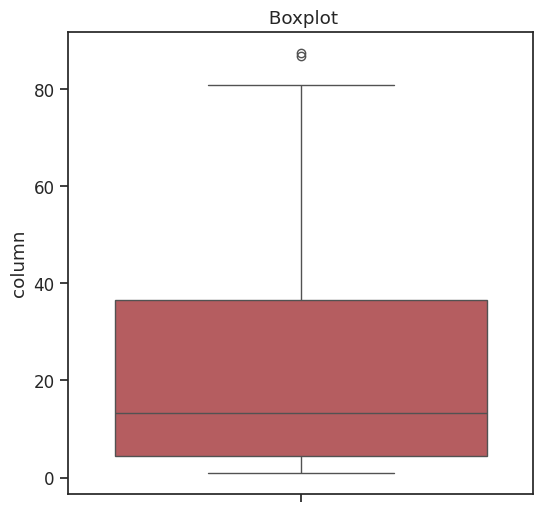

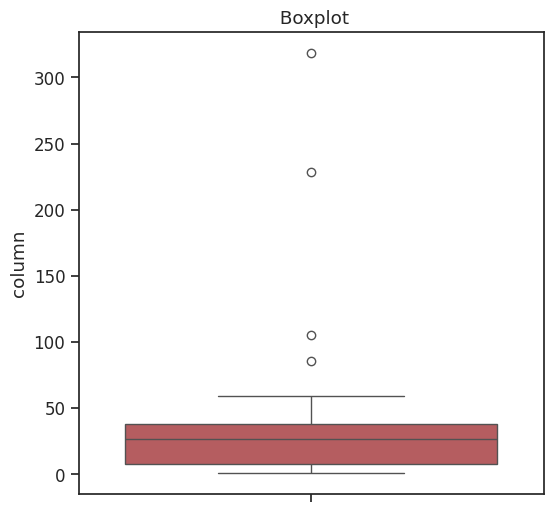

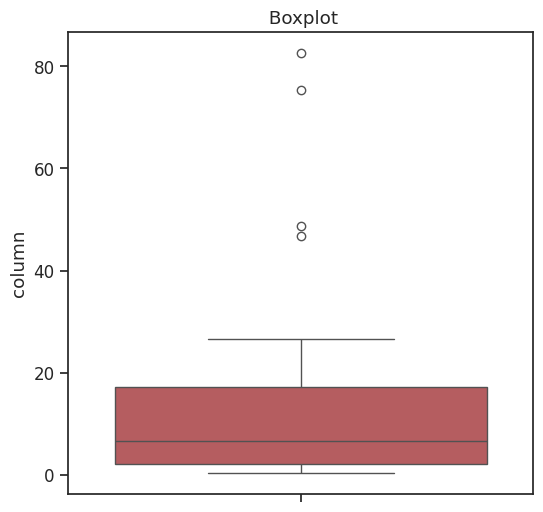

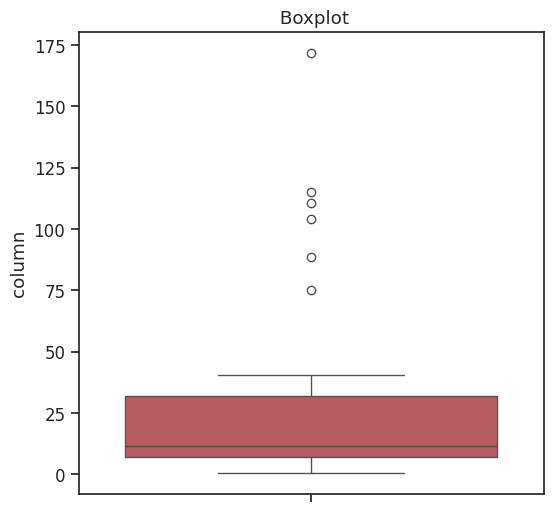

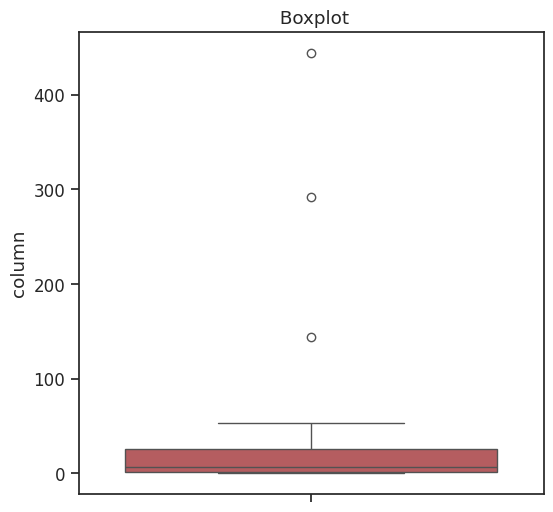

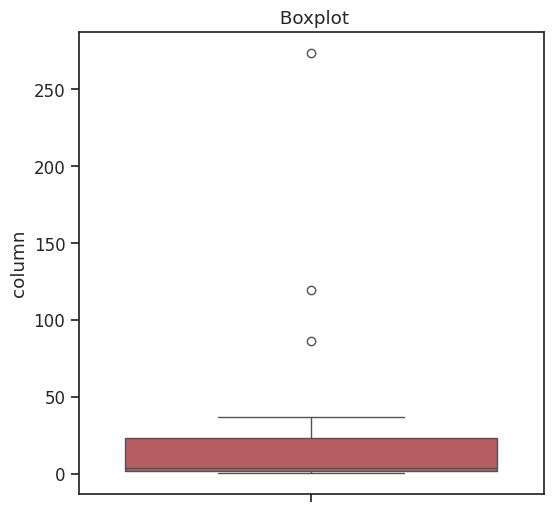

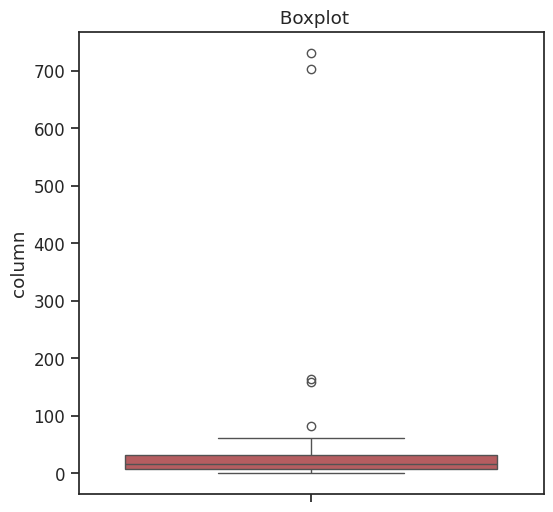

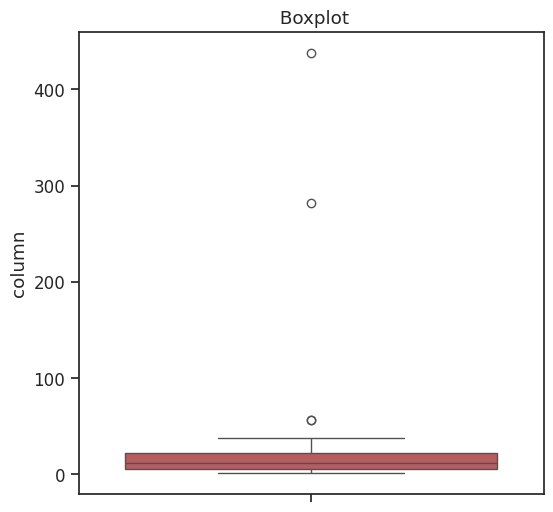

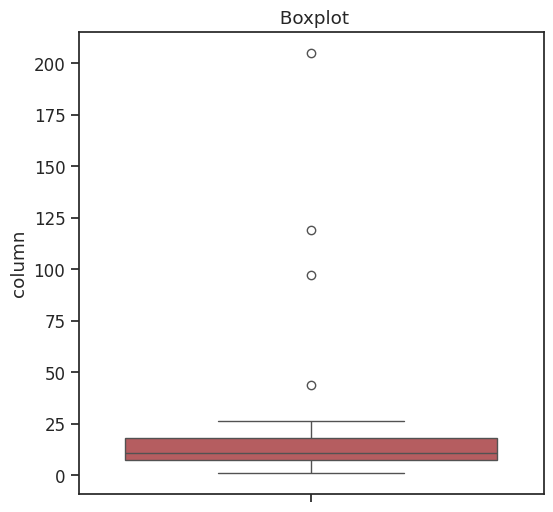

In [6]:
import warnings
warnings.filterwarnings("ignore")
numerical_columns = ds.select_dtypes(include=['int64', 'float64']).columns
for column in numerical_columns:
    import matplotlib.pyplot as plt
    import seaborn as sns

    plt.figure(figsize=(6, 6))
    sns.boxplot( y=column, data=ds,color='r')
    plt.title(f' Boxplot')
    plt.ylabel('column')
    plt.show()

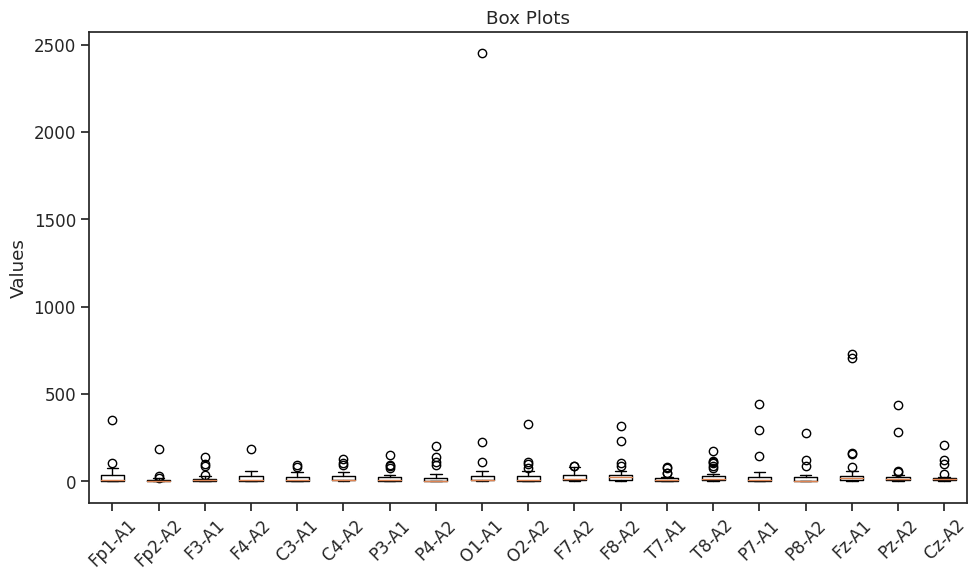

In [7]:
#Box plot for each column
fig, ax = plt.subplots(figsize=(10, 6))
plt.boxplot(selected_columns.values, labels=selected_columns.columns)
plt.xticks(rotation=45)
plt.ylabel('Values')
plt.title('Box Plots')
plt.tight_layout()
plt.show()

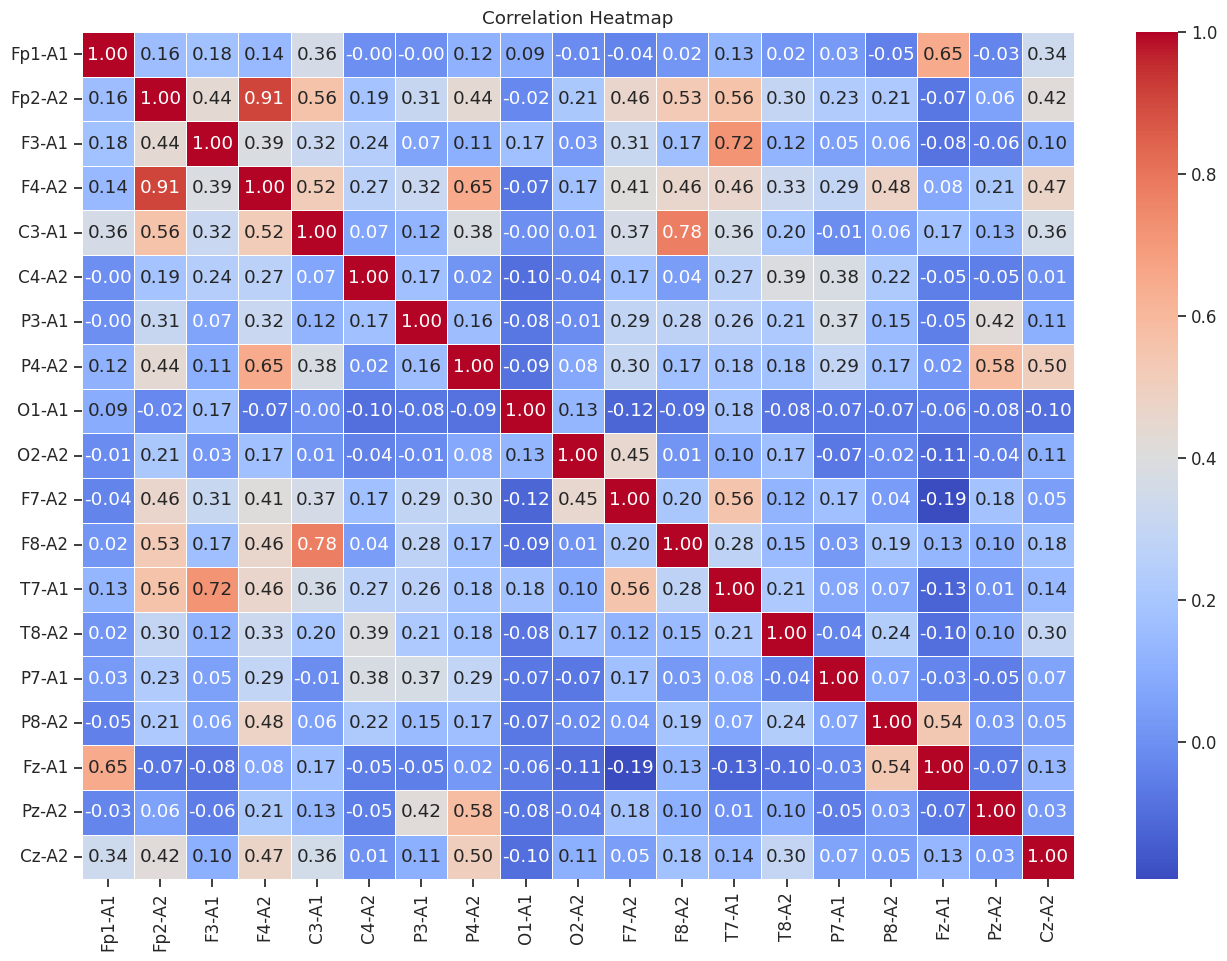

In [8]:
# Calculate the correlation matrix
correlation_matrix = selected_columns.corr()

# Create a heatmap
plt.figure(figsize=(16, 11))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

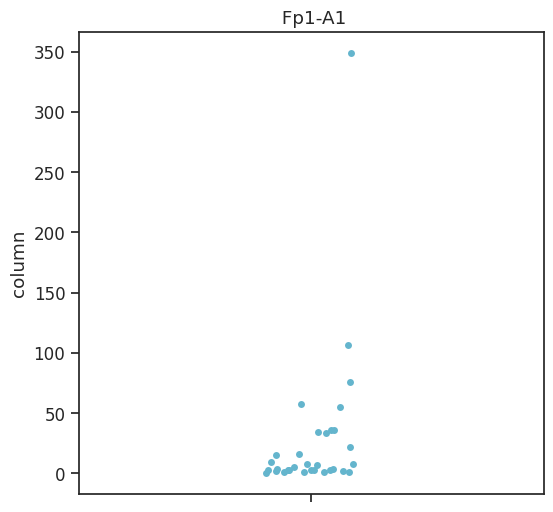

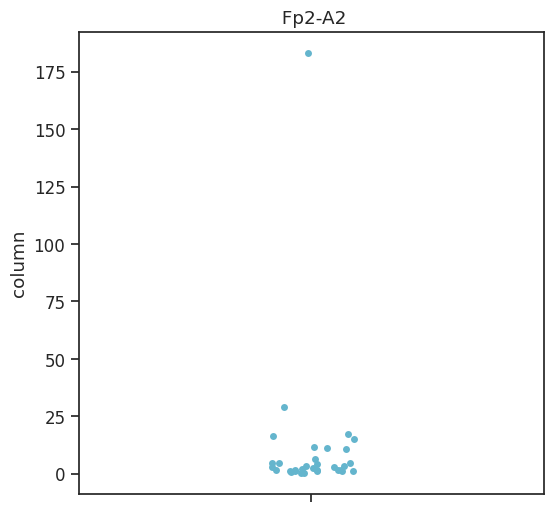

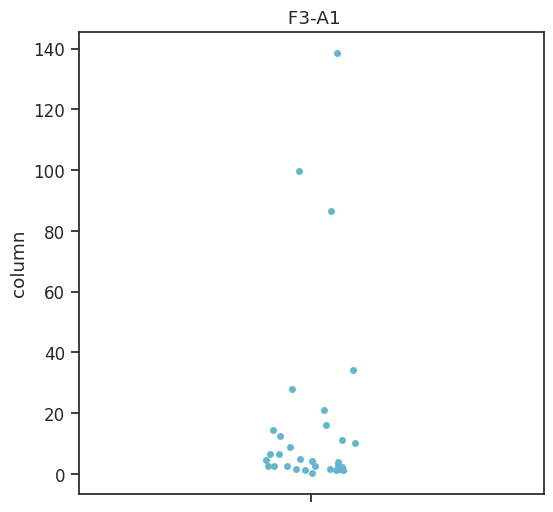

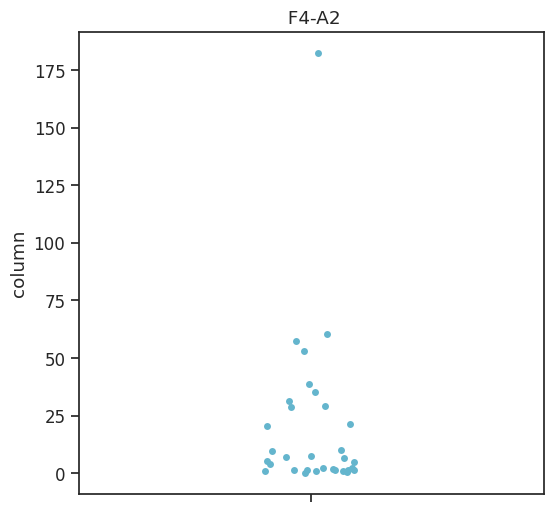

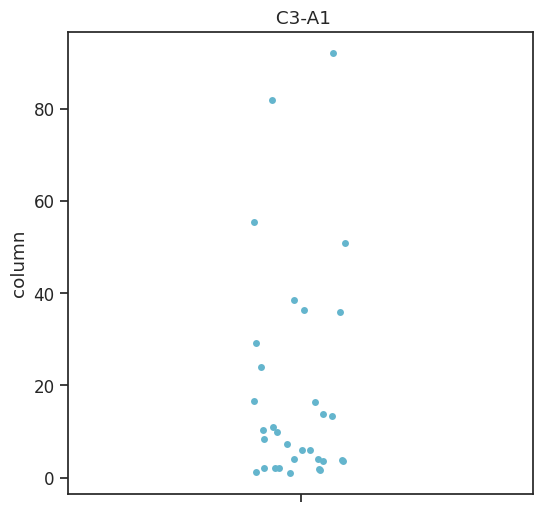

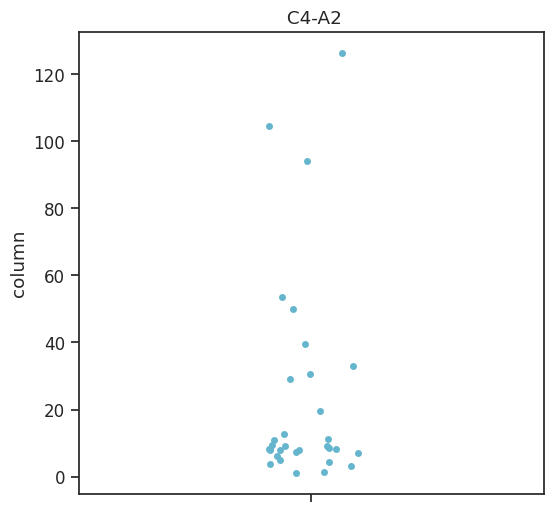

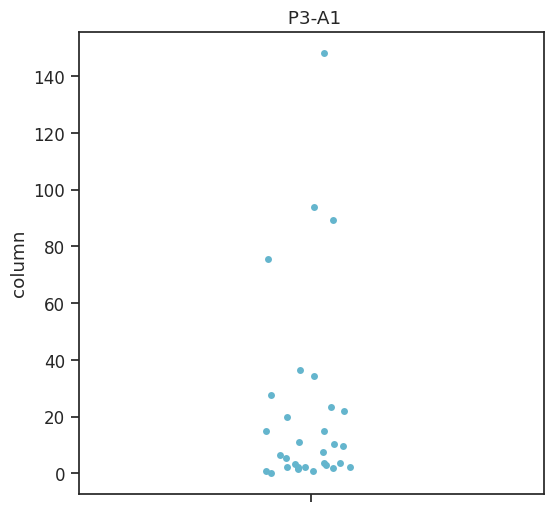

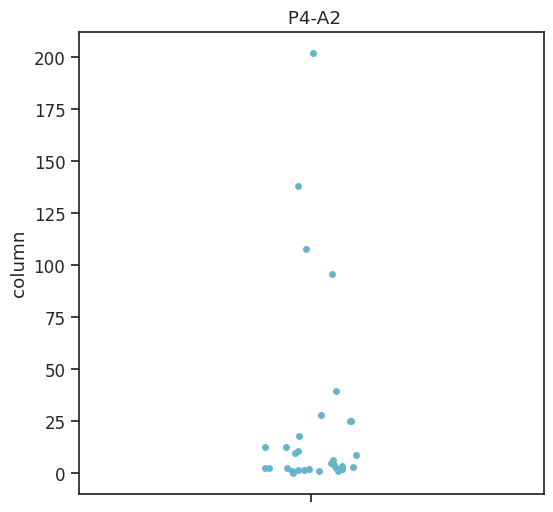

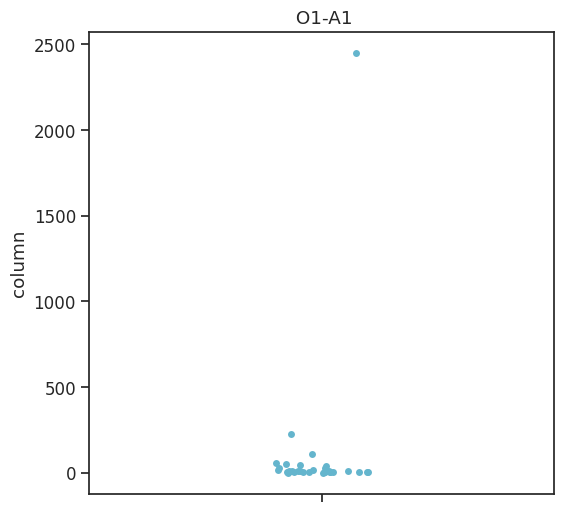

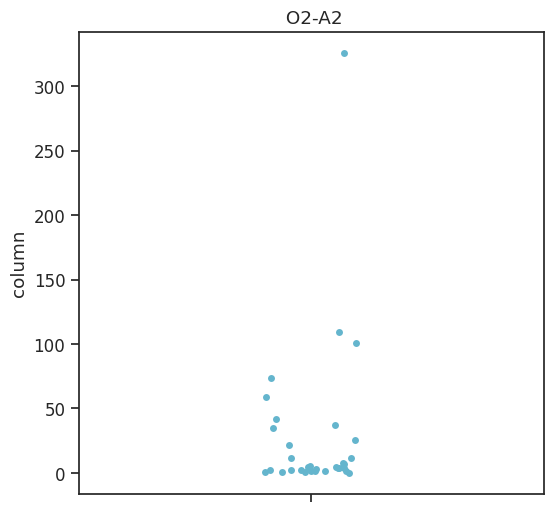

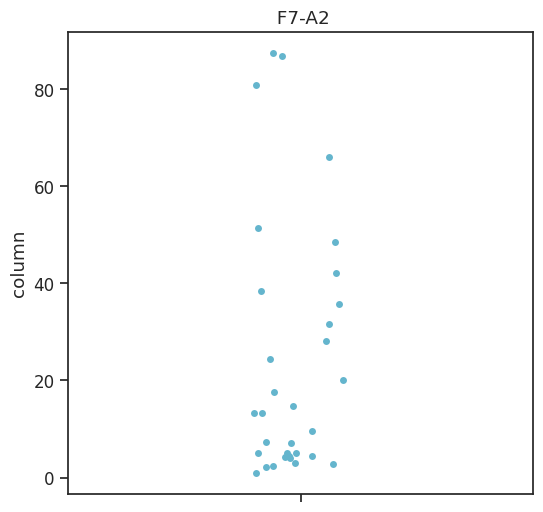

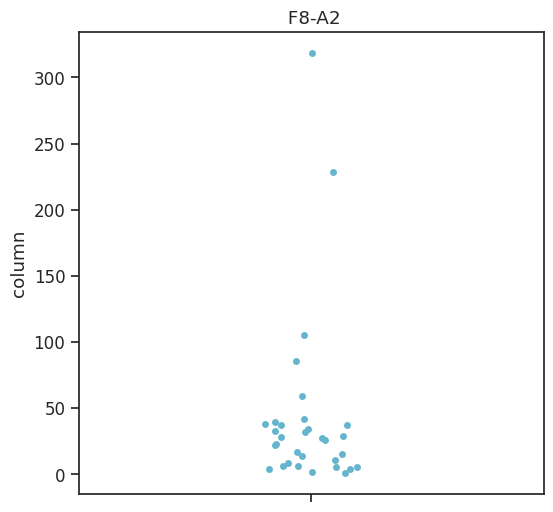

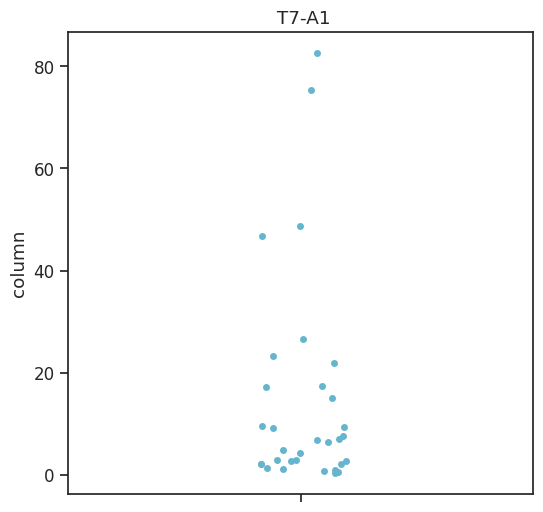

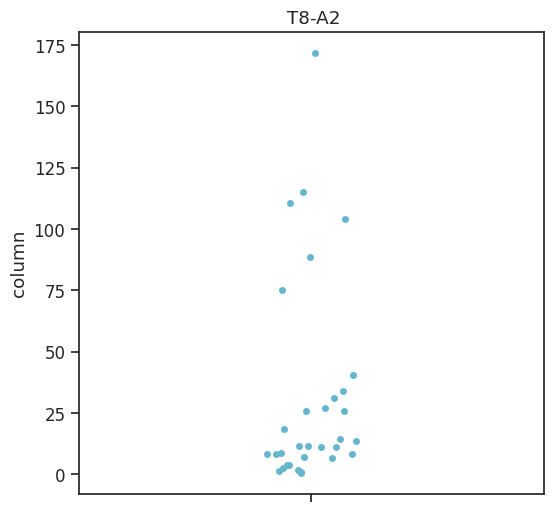

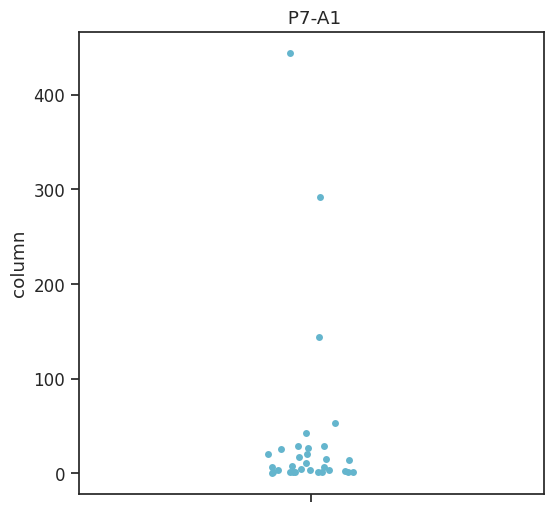

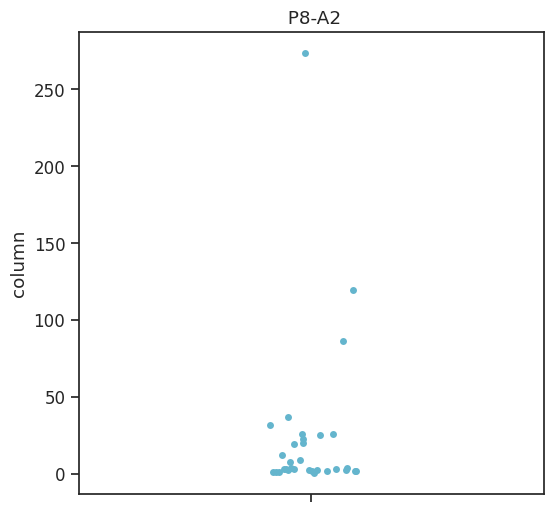

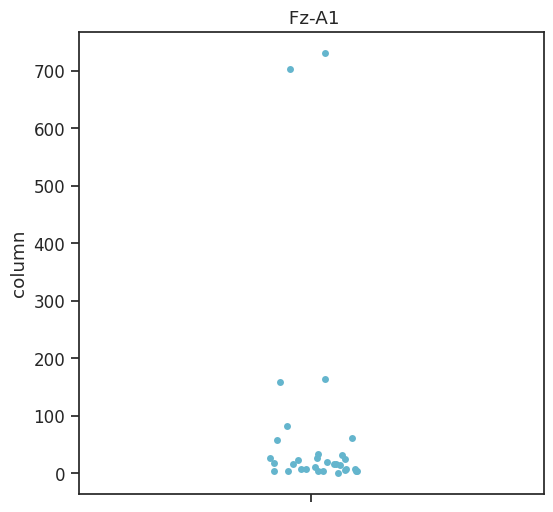

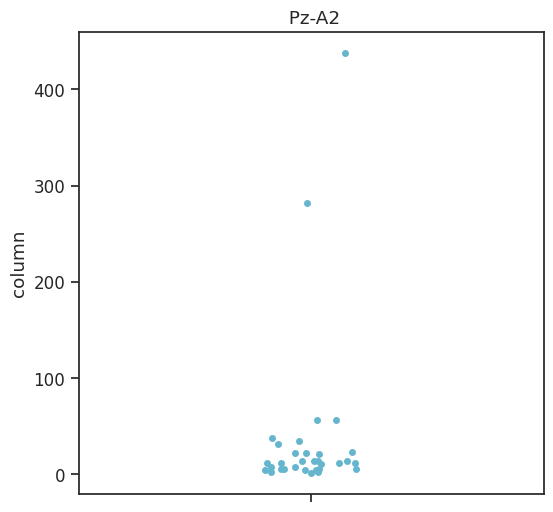

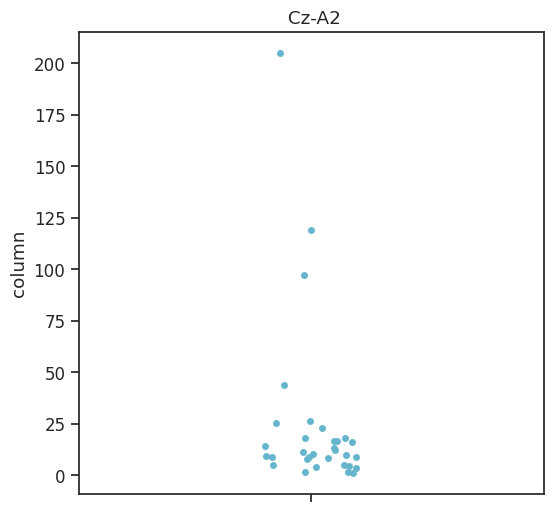

In [9]:
import warnings
warnings.filterwarnings("ignore")
numerical_columns = ds.select_dtypes(include=['int64', 'float64']).columns
for column in numerical_columns:
    import matplotlib.pyplot as plt
    import seaborn as sns

    plt.figure(figsize=(6, 6))
    sns.stripplot( y=column, data=ds,color='c')
    plt.title(f' {column}')
    plt.ylabel('column')
    plt.show()

## Part II: Skewness Distribution & Spatial Asymmetry Analysis (Alpha Band)

In [1]:
import pandas as pd
My_path = '../data/extracted_features/skew_neg.csv'
ds = pd.read_csv(My_path)

In [2]:
data= ds.dropna()
print(data.head())

         Fp1-A1    Fp2-A2         F3-A1     F4-A2     C3-A1     C4-A2  \
0 -5.246612e-01  0.143219  1.200751e-01 -0.259160  0.173656  1.785204   
1  2.120000e-05  0.000005 -5.910000e-06  0.000002  0.000001  0.000005   
2 -6.910000e-06  0.000005 -1.030000e-05  0.000006  0.000012  0.000008   
3  6.550000e-07  0.000001 -7.300000e-07 -0.000002 -0.000003  0.000001   
4  4.660000e-06  0.000004  5.460000e-06  0.000001  0.000003 -0.000001   

      P3-A1         P4-A2     O1-A1     O2-A2         F7-A2         F8-A2  \
0  1.465554  8.400789e-01 -0.041980  0.020076  1.149046e+00  1.273702e-01   
1 -0.000001 -2.420000e-07  0.000331  0.000017  3.500000e-07 -4.610000e-06   
2  0.000002  2.440000e-06  0.000002  0.000004  1.440000e-06  1.100000e-05   
3 -0.000001 -2.820000e-06  0.000002 -0.000003 -2.710000e-06  4.620000e-06   
4  0.000008  2.120000e-06 -0.000006 -0.000017  9.210000e-07 -5.610000e-07   

          T7-A1     T8-A2         P7-A1         P8-A2     Fz-A1     Pz-A2  \
0  1.255656e-02 -0.09

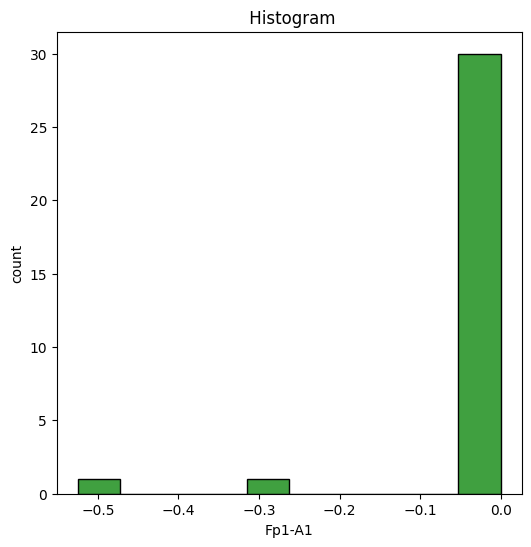

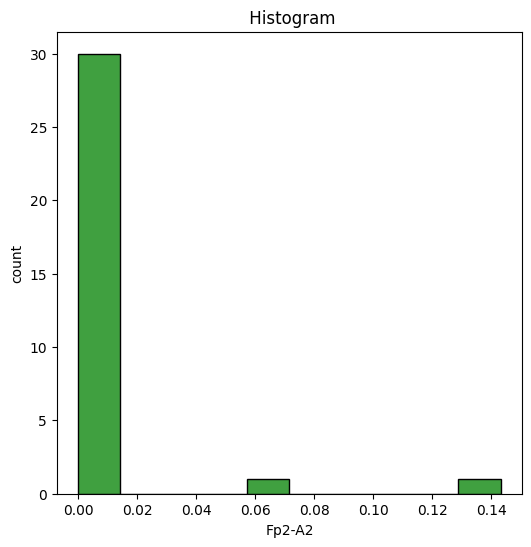

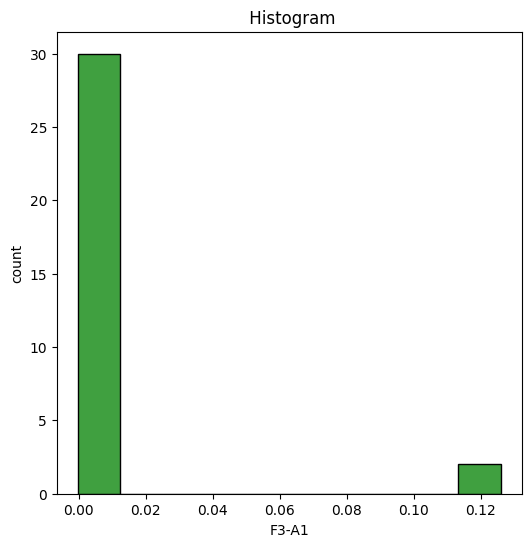

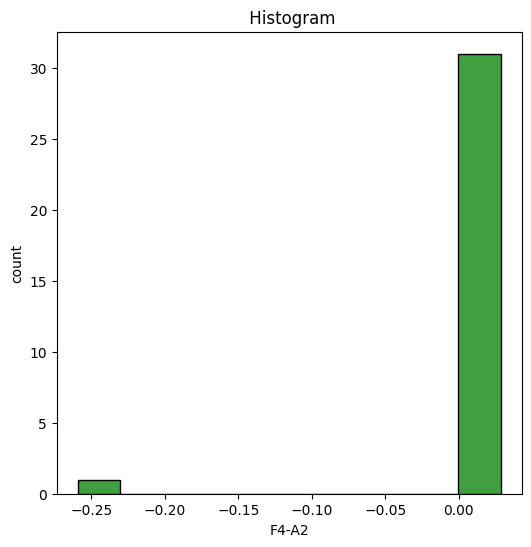

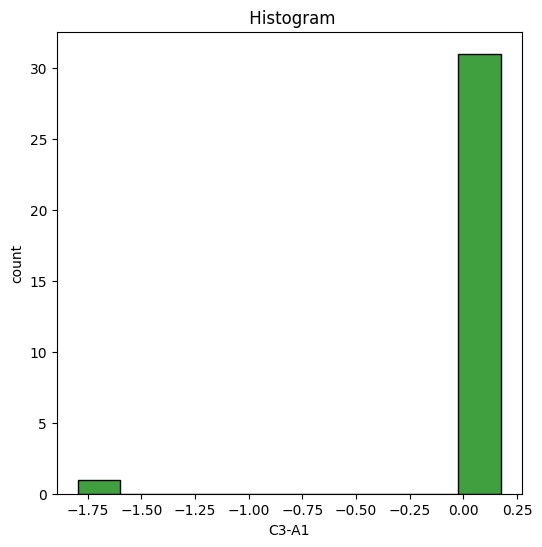

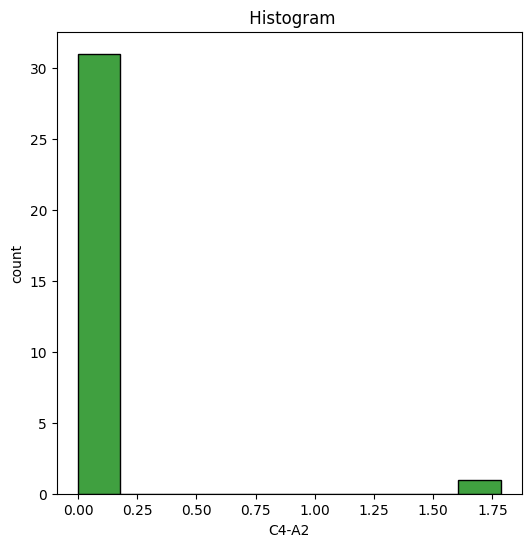

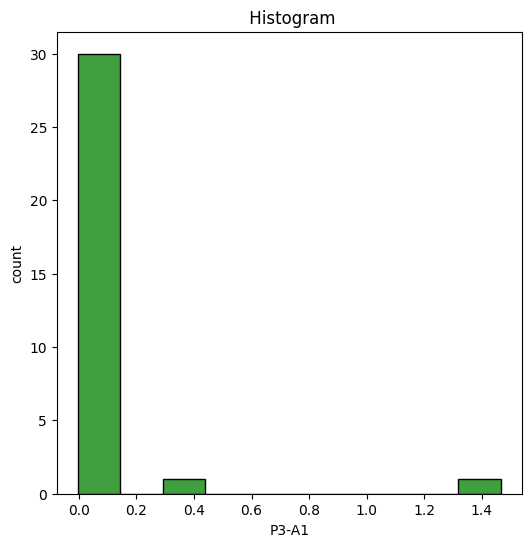

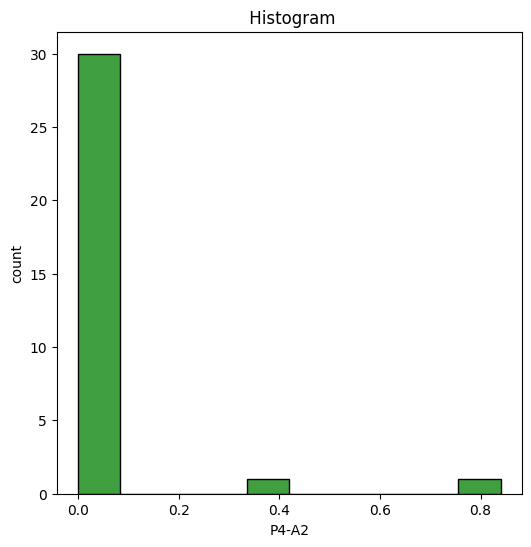

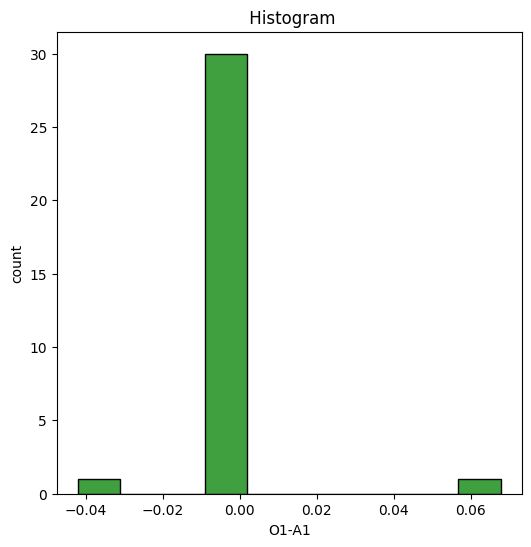

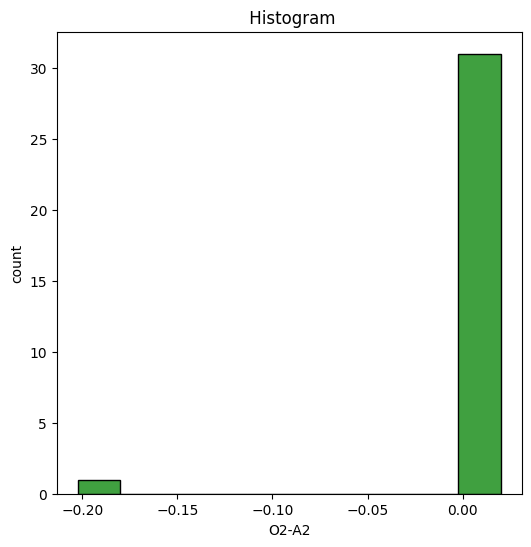

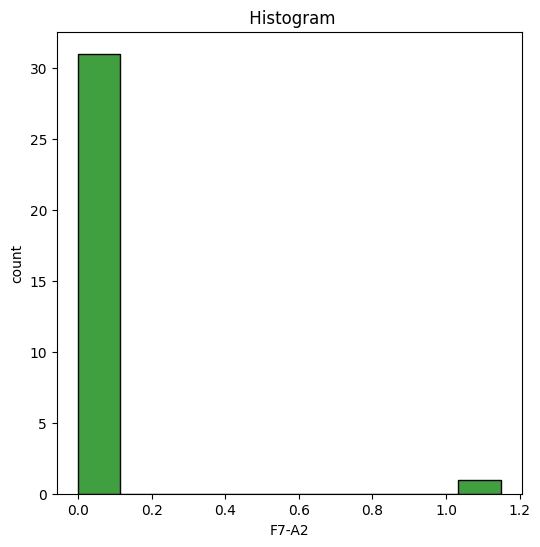

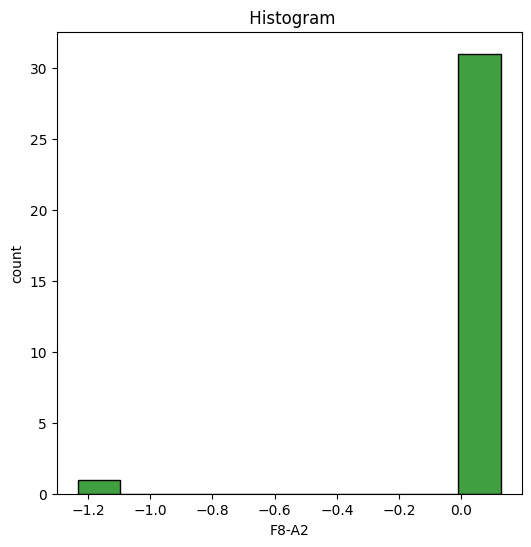

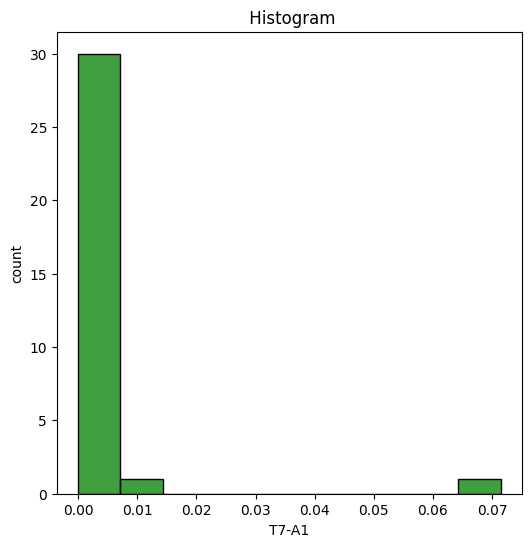

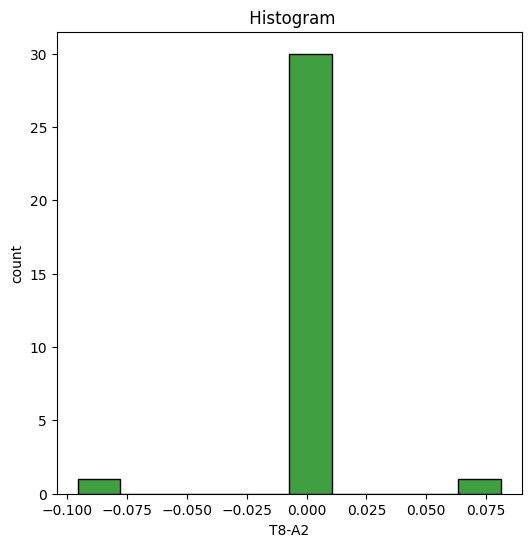

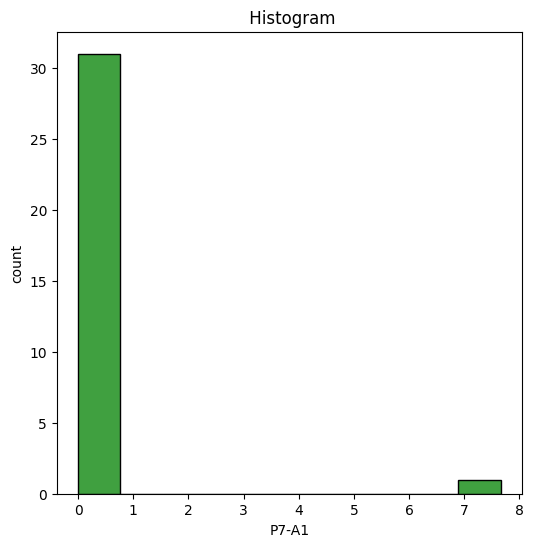

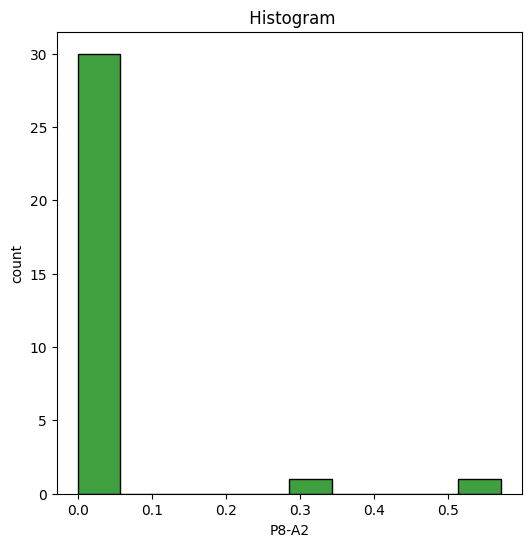

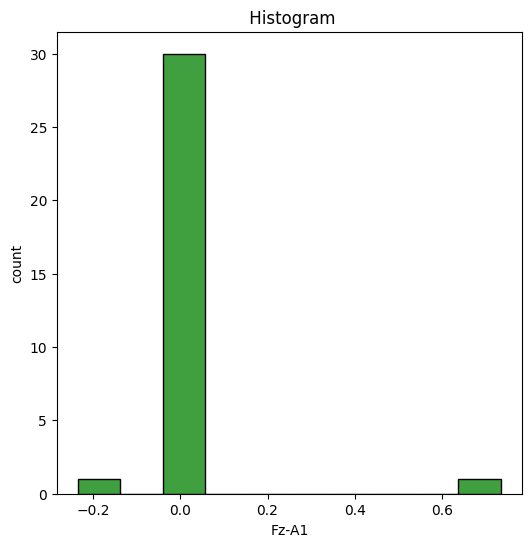

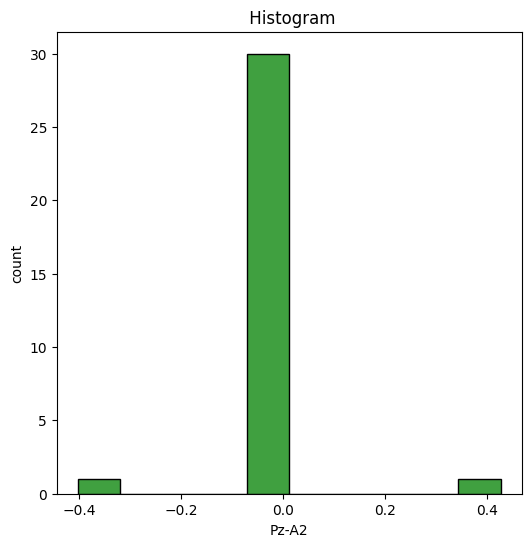

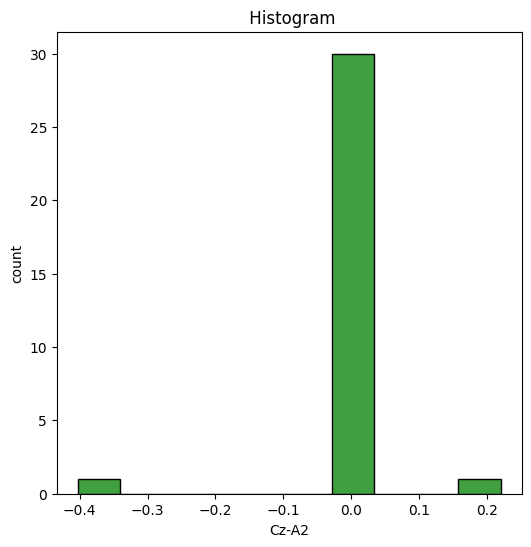

In [3]:
import warnings
warnings.filterwarnings("ignore")
numerical_columns = ds.select_dtypes(include=['int64', 'float64']).columns
for column in numerical_columns:
    import matplotlib.pyplot as plt
    import seaborn as sns

    plt.figure(figsize=(6, 6))
    sns.histplot( x=column, data=ds,bins=10,color='g')
    plt.title(f' Histogram')
    plt.ylabel('count')
    plt.show()

In [4]:
# Select all columns except the last one
selected_columns = data.iloc[:, :-1]

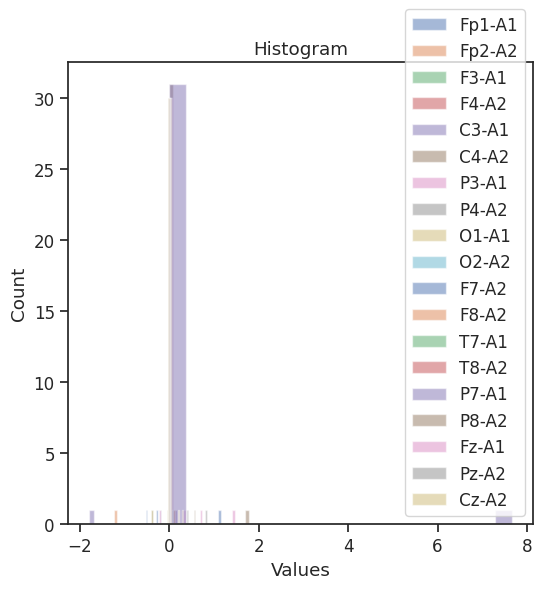

In [5]:
# Histogram
sns.set(style='ticks', palette='deep', font_scale=1.1)
fig, ax = plt.subplots(figsize=(6, 6))
for col in selected_columns.columns:
    plt.hist(selected_columns[col], bins=20, alpha=0.5, label=col)
plt.xlabel('Values')
plt.ylabel('Count')
plt.title('Histogram')
plt.legend()
plt.show()

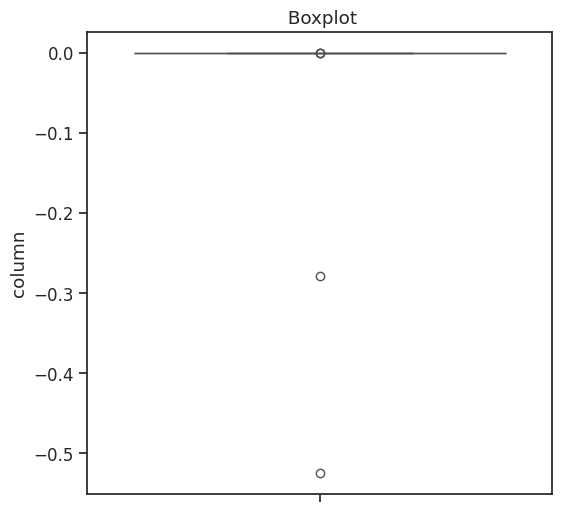

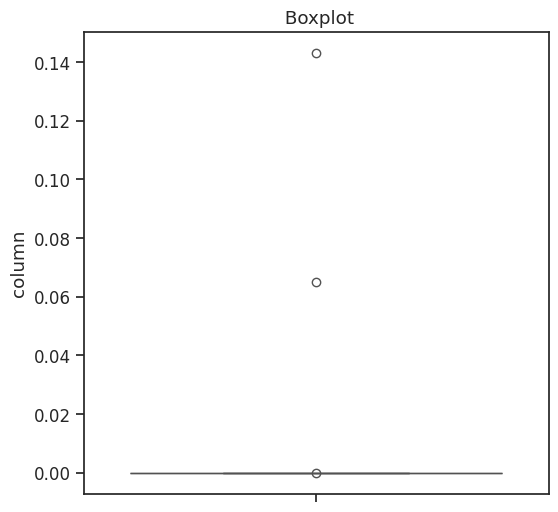

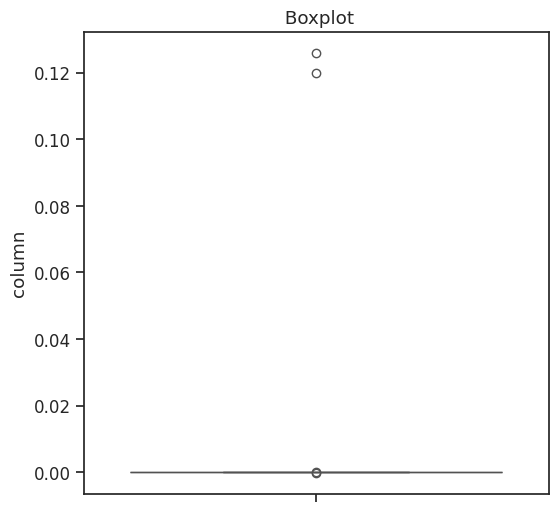

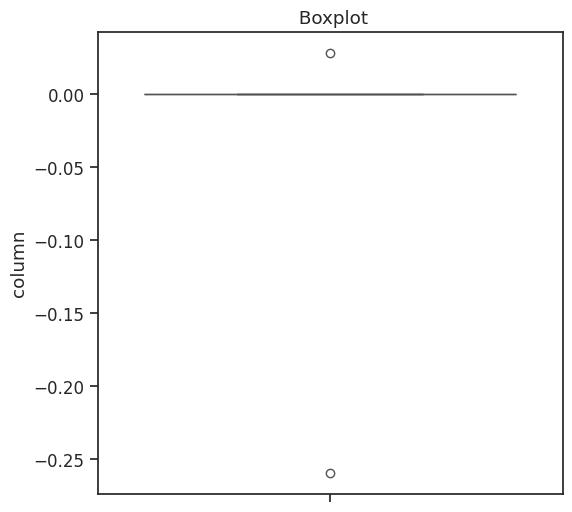

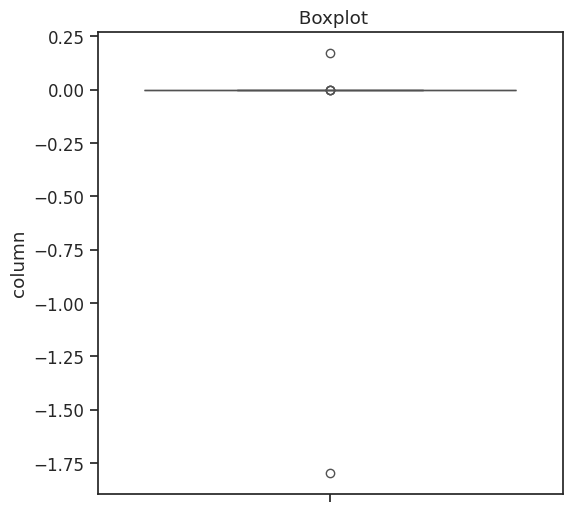

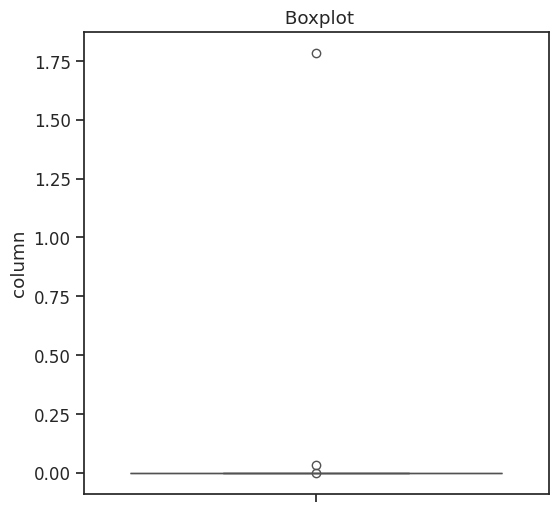

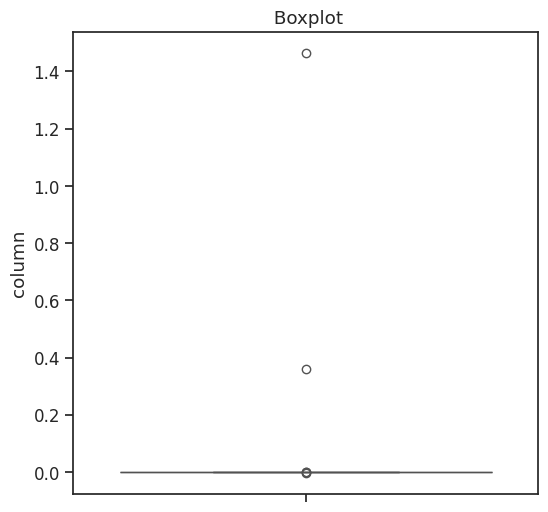

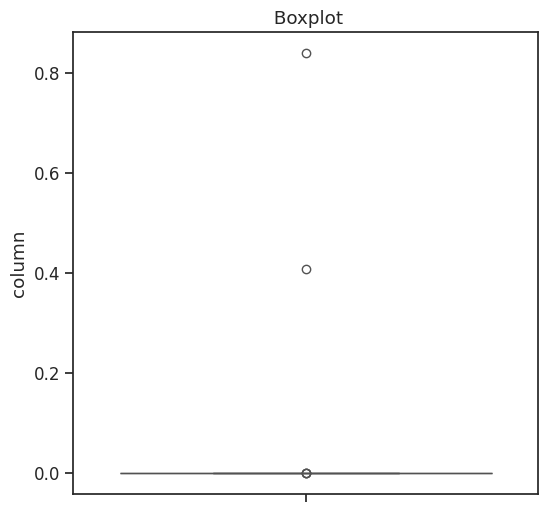

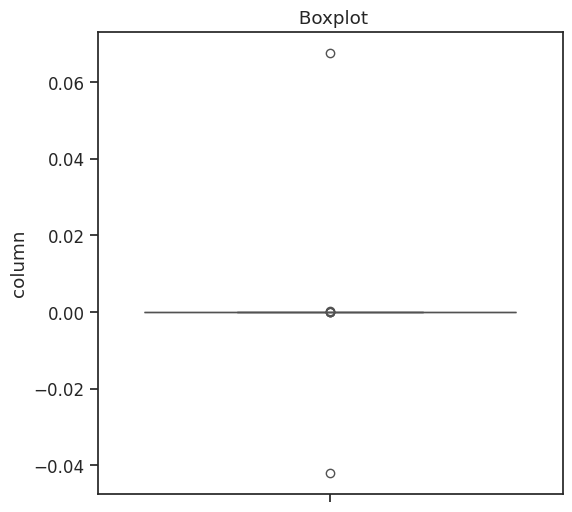

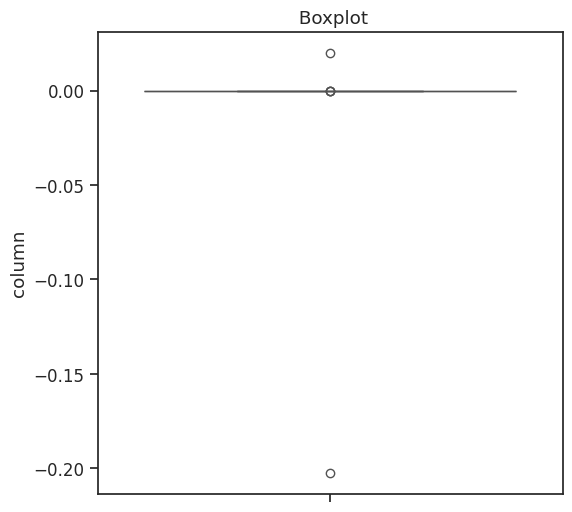

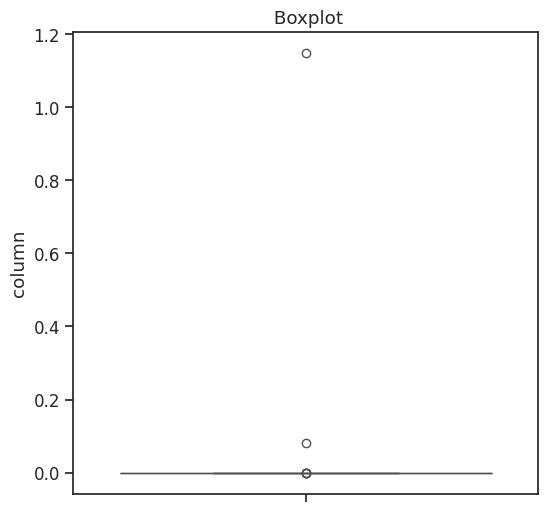

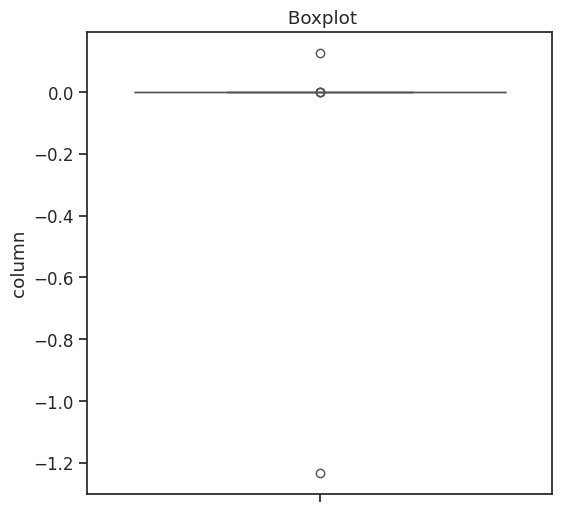

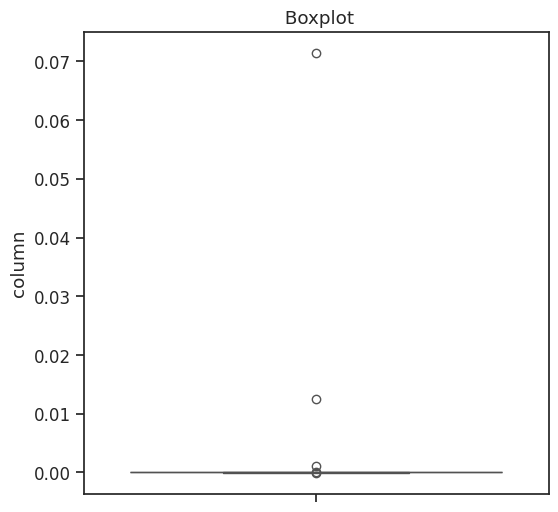

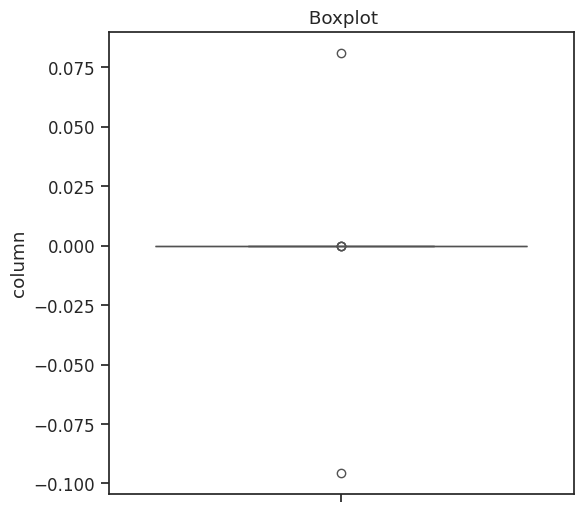

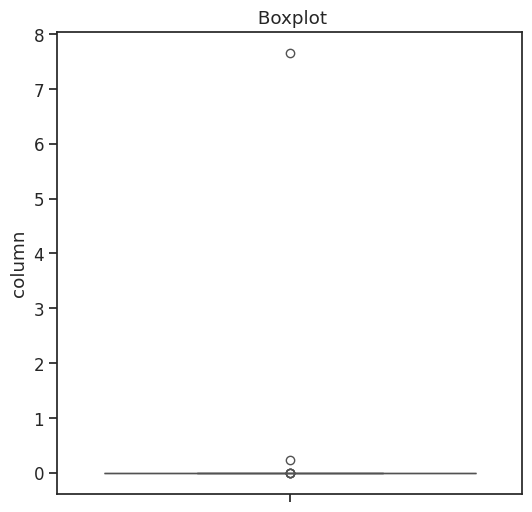

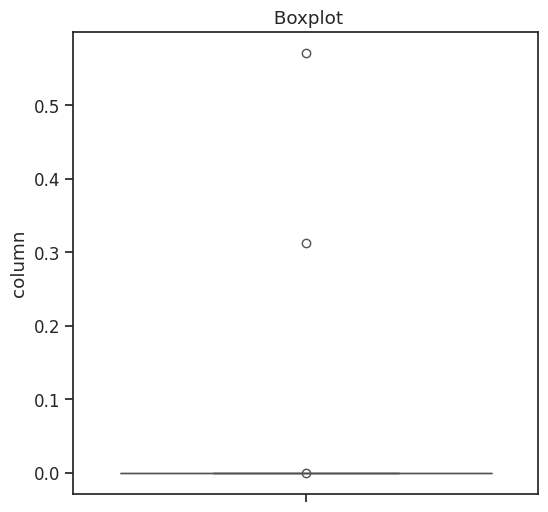

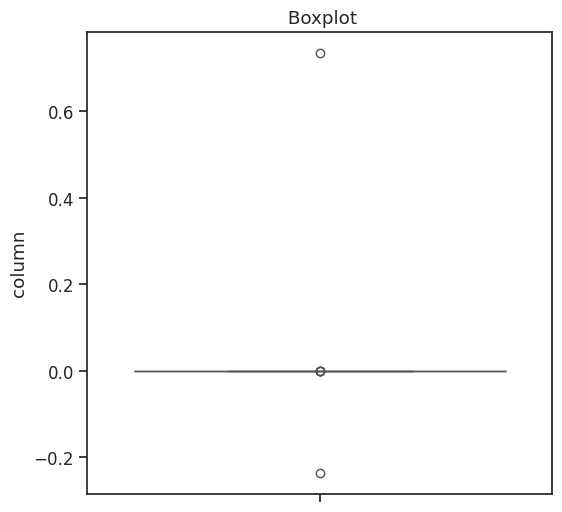

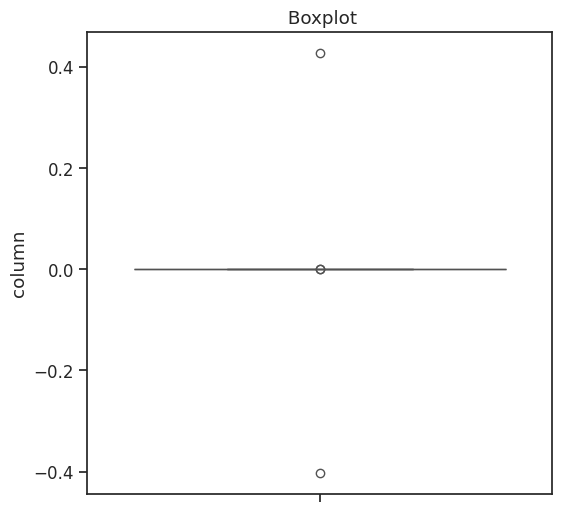

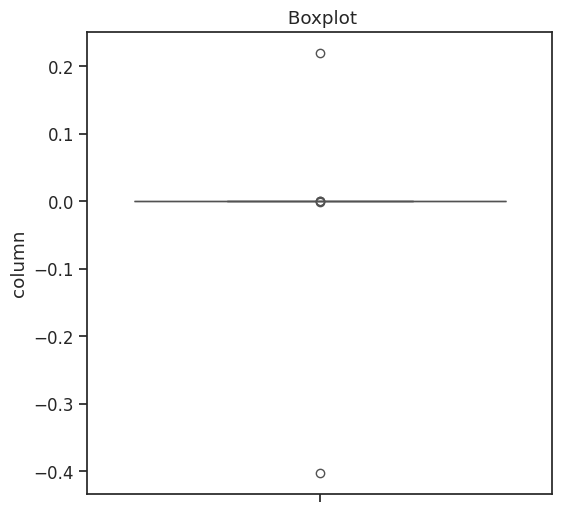

In [6]:
import warnings
warnings.filterwarnings("ignore")
numerical_columns = ds.select_dtypes(include=['int64', 'float64']).columns
for column in numerical_columns:
    import matplotlib.pyplot as plt
    import seaborn as sns

    plt.figure(figsize=(6, 6))
    sns.boxplot( y=column, data=ds,color='r')
    plt.title(f' Boxplot')
    plt.ylabel('column')
    plt.show()

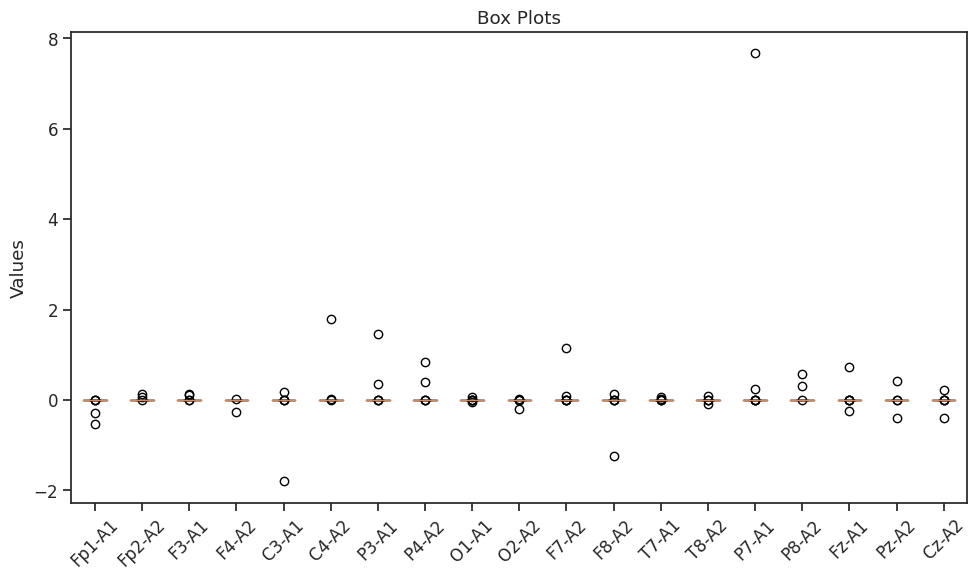

In [7]:
#Box plot for each column
fig, ax = plt.subplots(figsize=(10, 6))
plt.boxplot(selected_columns.values, labels=selected_columns.columns)
plt.xticks(rotation=45)
plt.ylabel('Values')
plt.title('Box Plots')
plt.tight_layout()
plt.show()

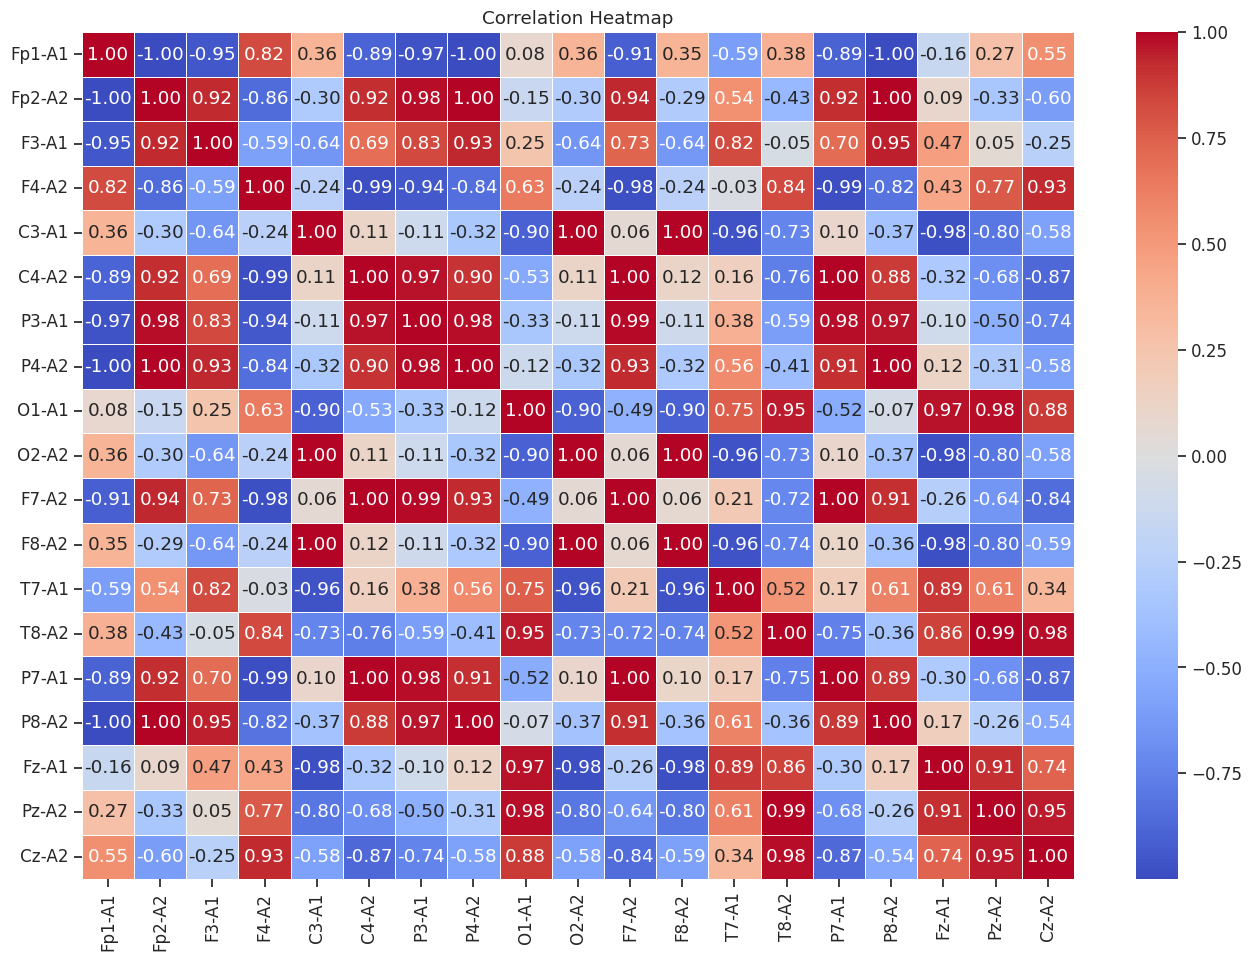

In [8]:
# Calculate the correlation matrix
correlation_matrix = selected_columns.corr()

# Create a heatmap
plt.figure(figsize=(16, 11))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

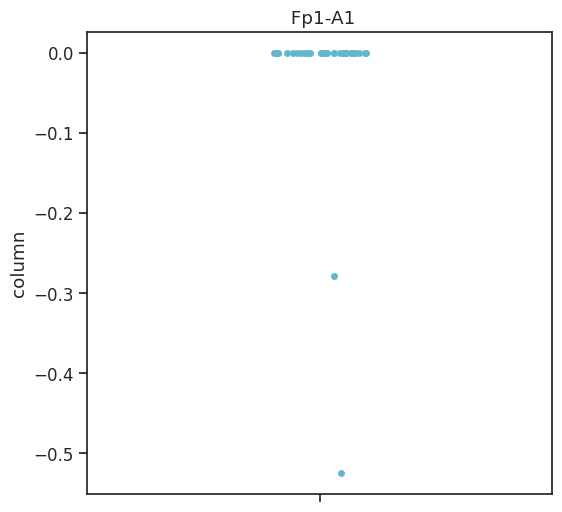

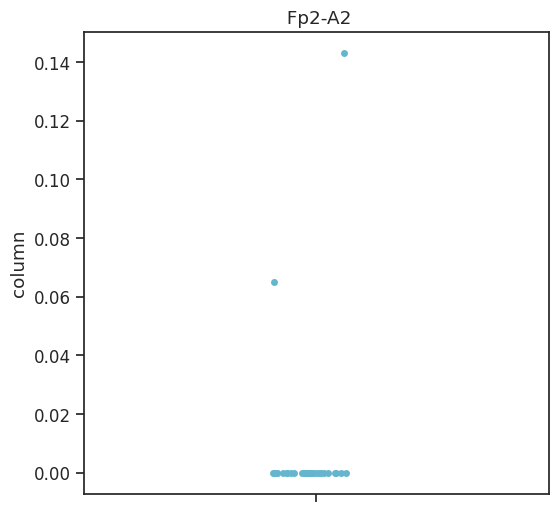

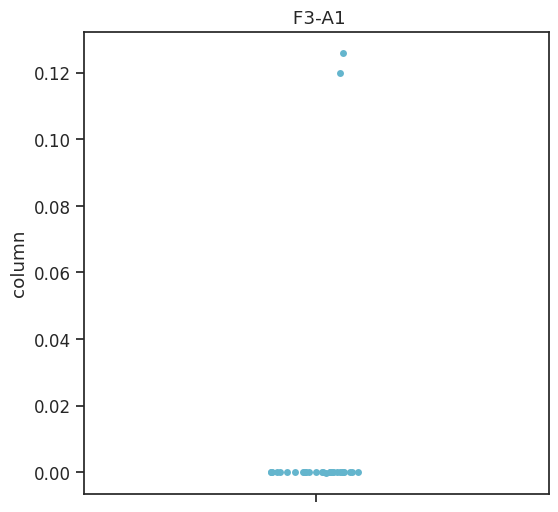

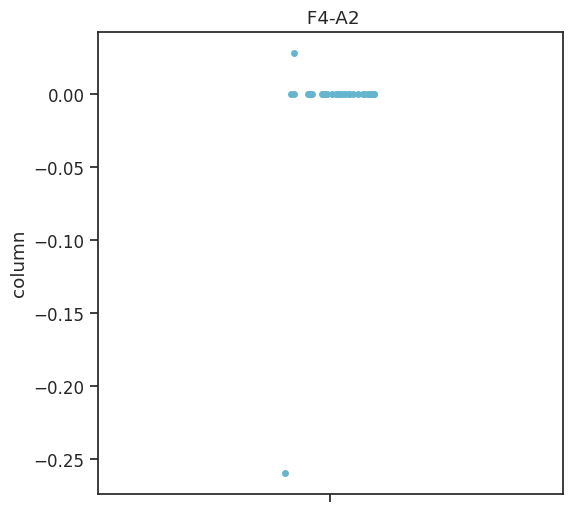

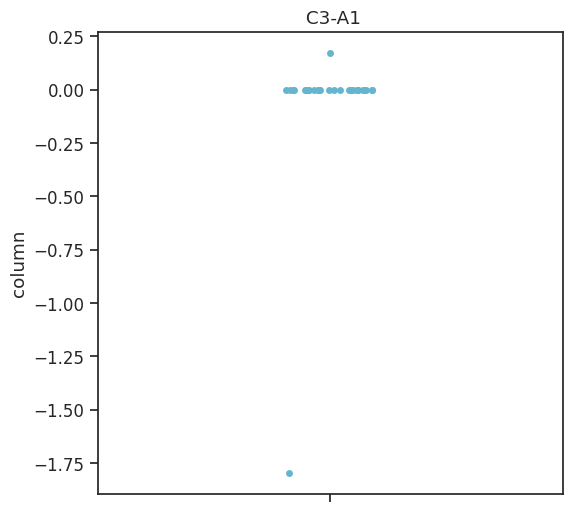

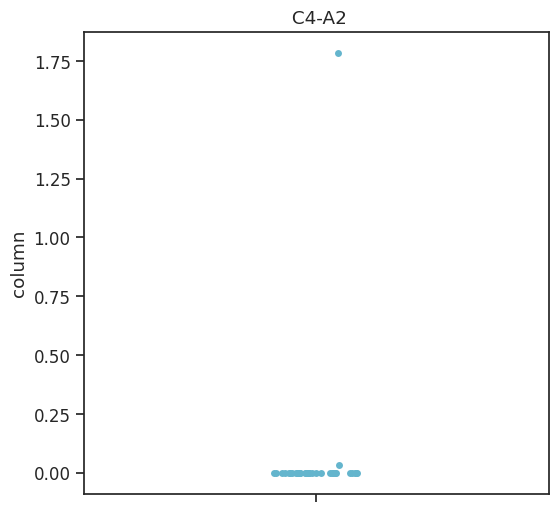

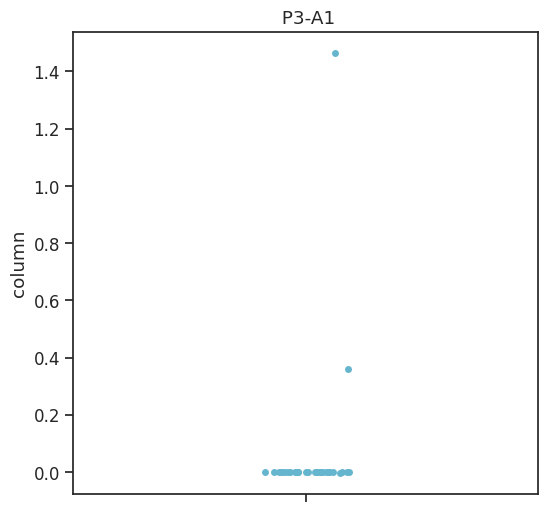

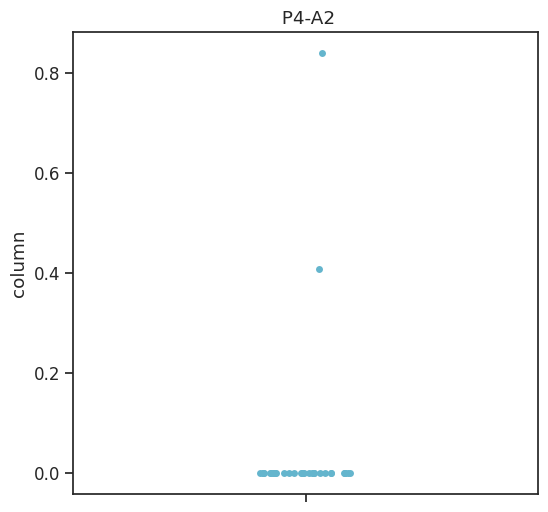

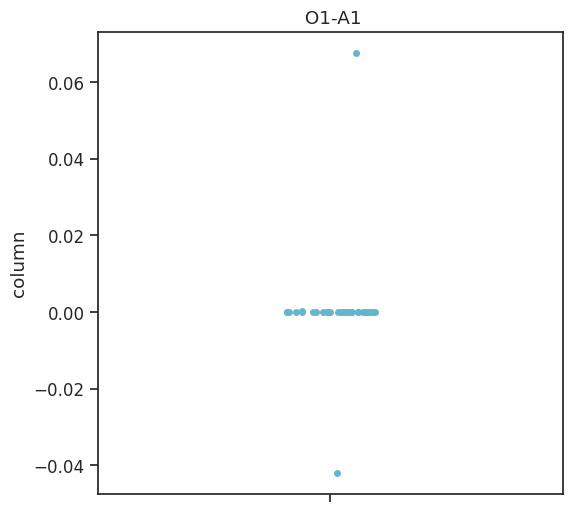

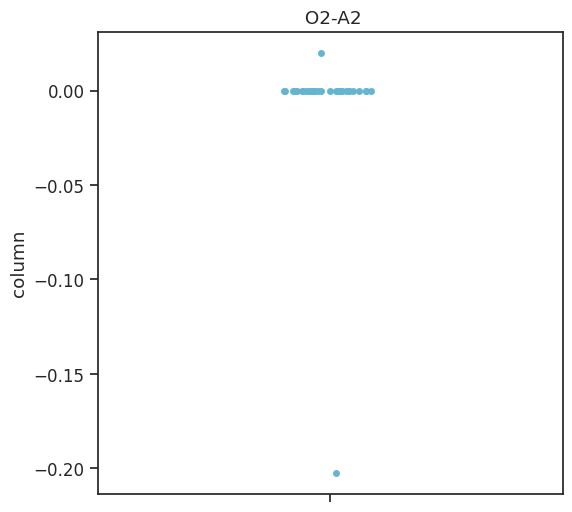

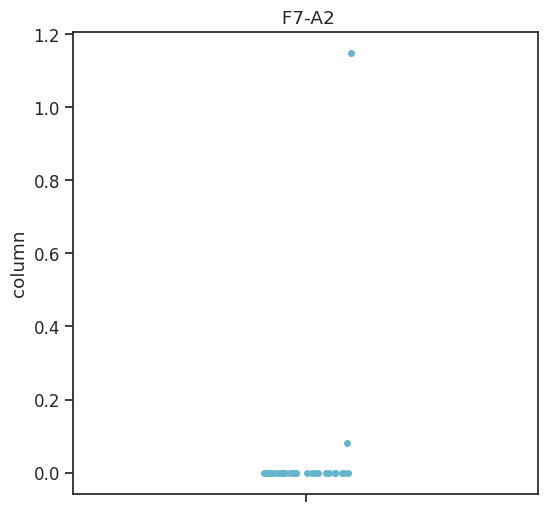

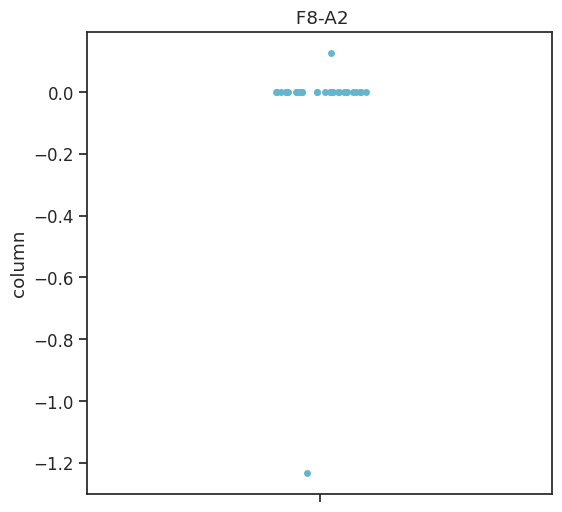

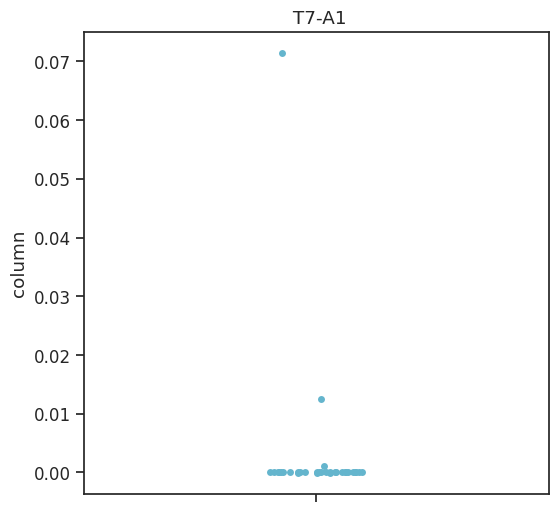

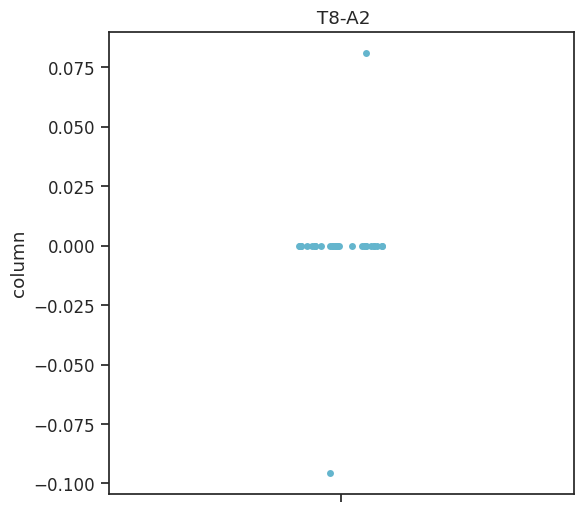

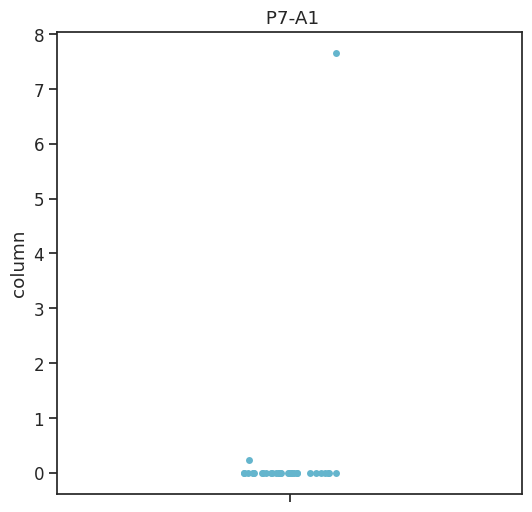

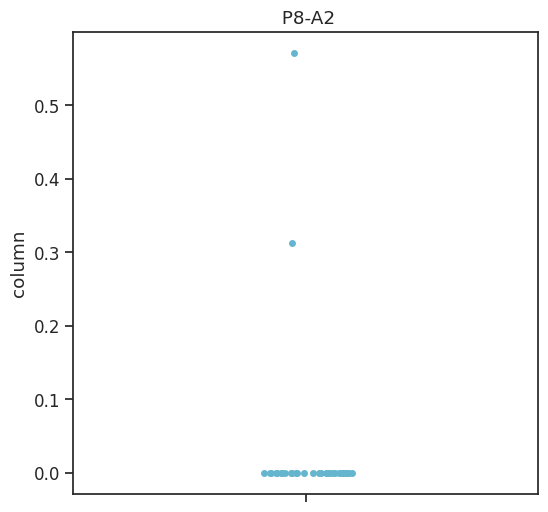

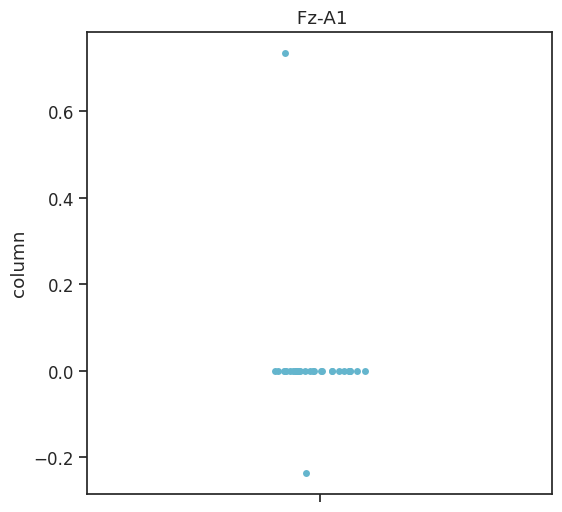

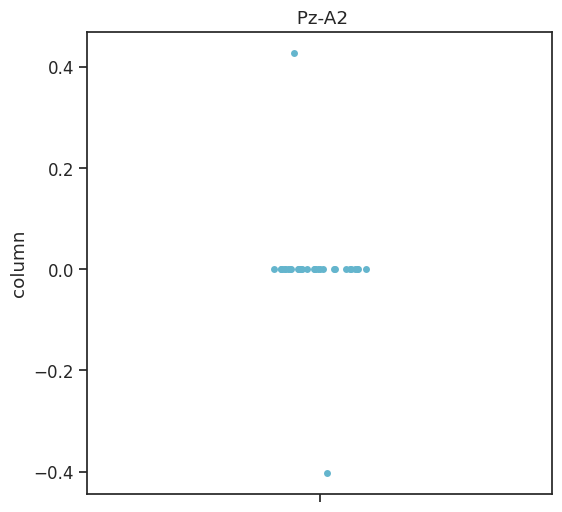

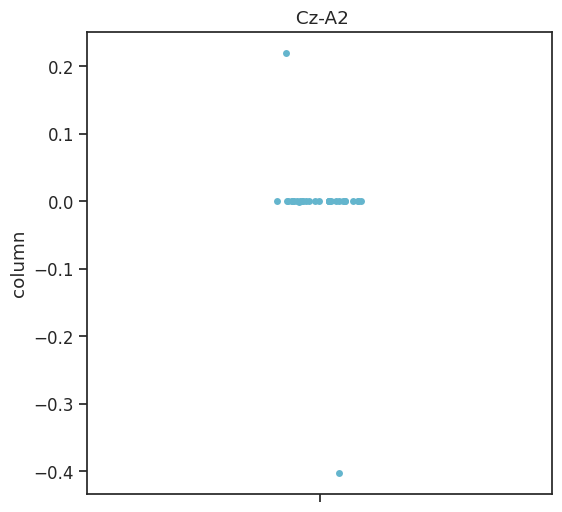

In [9]:
import warnings
warnings.filterwarnings("ignore")
numerical_columns = ds.select_dtypes(include=['int64', 'float64']).columns
for column in numerical_columns:
    import matplotlib.pyplot as plt
    import seaborn as sns

    plt.figure(figsize=(6, 6))
    sns.stripplot( y=column, data=ds,color='c')
    plt.title(f' {column}')
    plt.ylabel('column')
    plt.show()